# EDA 1. Credit Card Fraud Detection (ULB)

Проект: обнаружение мошеннических транзакций в условиях сильного дисбаланса классов.

Данные: [Kaggle – mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Это транзакции по картам европейских клиентов за два дня в сентябре 2013 года, датасет выложили Worldline и ML Group из ULB.

Признаки:
- `Time` – сколько секунд прошло с первой транзакции в датасете
- `V1`–`V28` – главные компоненты после PCA, исходные признаки авторы не раскрывают из-за конфиденциальности
- `Amount` – сумма операции, ее через PCA не пропускали
- `Class` – таргет, 1 значит мошенничество

Так как признаки уже после PCA, интерпретировать их мы не сможем. Поэтому в этом ноутбуке больше смотрим на дисбаланс, на то, насколько классы вообще разделимы, на выбросы, дубликаты и на то, как правильно разбить данные.

Чтобы запустить ноутбук, файл `creditcard.csv` нужно положить в папку `data/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import IsolationForest

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
PAL = {0: '#4C72B0', 1: '#D1495B'}
RS = 42

## 1. Загрузка и общий обзор

In [2]:
df = pd.read_csv('data/creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
df.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


Что видно из describe:
- все признаки числовые, категориальных нет, поэтому describe(include="all") выдает то же самое, что и обычный describe
- `V1`–`V28` в среднем около нуля, и std у них падает от `V1` к `V28`. Так и должно быть у PCA, компоненты отсортированы по объясненной дисперсии
- при этом min и max очень далеко от квартилей (например, `V5` от -114 до 35, а IQR около 1.3), то есть хвосты тяжелые
- `Time` от 0 до 172 792 секунд, ровно двое суток
- `Amount` от 0 до 25 691, медиана 22, а среднее 88, распределение сильно скошено вправо
- среднее по `Class` 0.0017, то есть мошенничества примерно 0.17%

## 2. Целевая переменная и степень дисбаланса

In [5]:
cnt = df['Class'].value_counts().sort_index()
share = df['Class'].value_counts(normalize=True).sort_index()
print(pd.DataFrame({'count': cnt, 'share': share.round(5)}))
print('Соотношение классов 1 :', round(cnt[0] / cnt[1]))
print('PR-AUC случайного классификатора (равна доле класса 1):', round(share[1], 5))

        count    share
Class                 
0      284315  0.99827
1         492  0.00173
Соотношение классов 1 : 578
PR-AUC случайного классификатора (равна доле класса 1): 0.00173


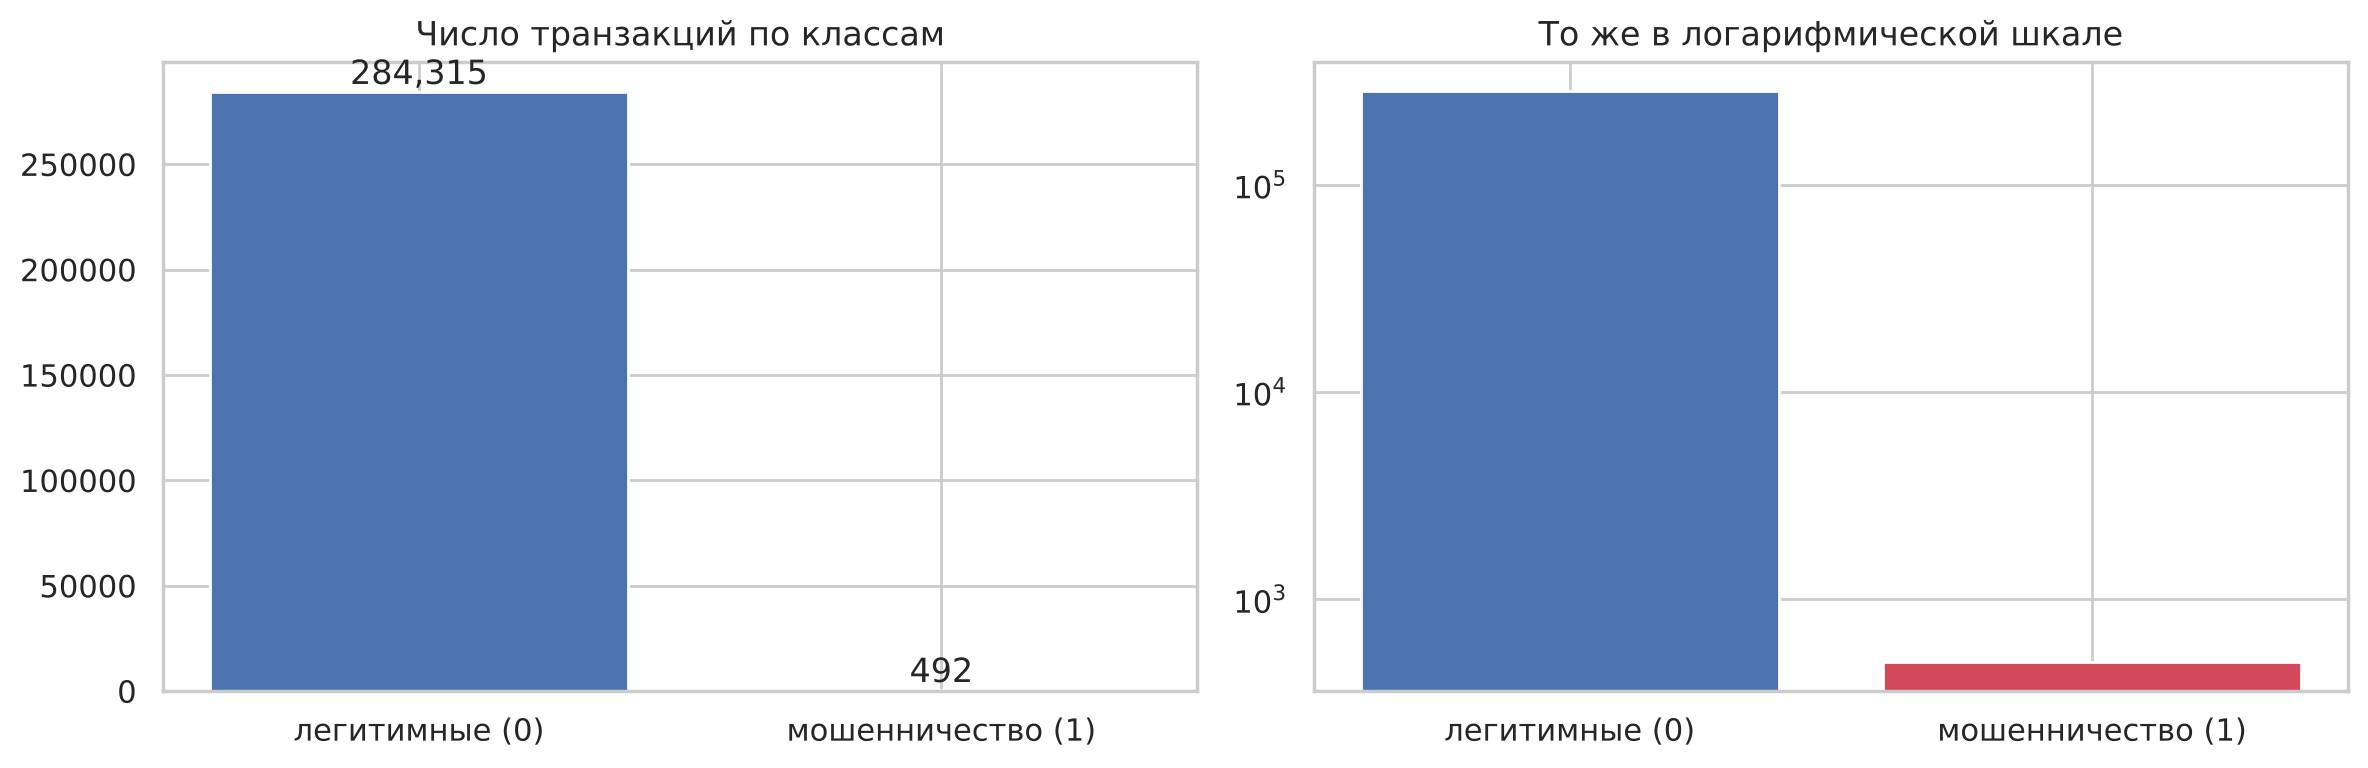

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['легитимные (0)', 'мошенничество (1)'], cnt.values, color=[PAL[0], PAL[1]])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
axes[0].set_title('Число транзакций по классам')
axes[1].bar(['легитимные (0)', 'мошенничество (1)'], cnt.values, color=[PAL[0], PAL[1]])
axes[1].set_yscale('log')
axes[1].set_title('То же в логарифмической шкале')
plt.tight_layout()
plt.show()

Дисбаланс очень сильный, примерно 578 нормальных операций на одну мошенническую. Что из этого следует:
- accuracy смотреть бессмысленно, если всегда отвечать "0", получим 99.83%
- ROC-AUC тоже будет выглядеть слишком хорошо, потому что FPR считается от огромного числа негативов. Поэтому основная метрика у нас PR-AUC, у случайной модели она равна доле класса, то есть 0.0017
- положительных объектов всего 492, в тест попадет порядка сотни, поэтому метрики на тесте будут шумными (ниже проверим это бутстрепом)

## 3. Пропущенные значения

In [7]:
na = df.isna().sum().to_frame('n_missing')
na['share'] = na['n_missing'] / len(df)
print('Всего пропусков:', int(na['n_missing'].sum()))
print('Доля пропущенных ячеек во всей таблице:', na['n_missing'].sum() / df.size)
na.T

Всего пропусков: 0
Доля пропущенных ячеек во всей таблице: 0.0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
n_missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
share,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Явных пропусков нет совсем. Для `V1`–`V28` это логично: PCA не умеет работать с NaN, так что пропуски либо заполнили, либо выкинули еще до публикации.

Но может быть скрытый пропуск в `Amount`, единственном признаке в исходных единицах. Нулевая сумма у операции по карте, скорее всего, не покупка за 0, а служебная операция: проверка карты без списания денег (так бывает, например, когда привязываешь карту к сервису или подписке). Мошенники часто проверяют украденные карты как раз такими операциями. Если гипотеза верна, среди нулевых сумм мошенничества должно быть больше.

In [8]:
zero_amt = df['Amount'].eq(0)
print('Операций с нулевой суммой:', zero_amt.sum(), 'доля:', round(zero_amt.mean(), 5))
pd.DataFrame({
    'n': df.groupby(zero_amt)['Class'].size(),
    'n_fraud': df.groupby(zero_amt)['Class'].sum(),
    'fraud_rate': df.groupby(zero_amt)['Class'].mean(),
}).rename_axis('Amount == 0')

Операций с нулевой суммой: 1825 доля: 0.00641


,n,n_fraud,fraud_rate
Amount == 0,,,
False,282982,465,0.001643
True,1825,27,0.014795


In [9]:
ct = pd.crosstab(zero_amt, df['Class'])
chi2, p, _, _ = stats.chi2_contingency(ct)
print('chi2 =', round(chi2, 2), 'p-value =', p)

chi2 = 174.32 p-value = 8.439540445543762e-40


Среди операций с нулевой суммой мошенничество встречается примерно в 9 раз чаще (1.5% против 0.16%), и хи-квадрат говорит, что это не случайность. Так что гипотеза похожа на правду, хотя точно проверить ее нельзя, в описании датасета про такие операции ничего не сказано.

Нули не будем заменять на NaN и не будем удалять, это полезная информация. Добавим бинарный признак `is_zero_amount`, а саму сумму будем брать через `log1p`, ему ноль не мешает.

## 4. Ошибочные значения и дубликаты

In [10]:
checks = pd.Series({
    'Class вне {0, 1}': (~df['Class'].isin([0, 1])).sum(),
    'Amount < 0': (df['Amount'] < 0).sum(),
    'Time < 0': (df['Time'] < 0).sum(),
    'Time > 48 часов': (df['Time'] > 48 * 3600).sum(),
    'Time убывает между соседними строками': (df['Time'].diff() < 0).sum(),
    'Бесконечные значения': int(np.isinf(df.to_numpy()).sum()),
})
checks.to_frame('n_rows')

,n_rows
"Class вне {0, 1}",0
Amount < 0,0
Time < 0,0
Time > 48 часов,0
Time убывает между соседними строками,0
Бесконечные значения,0


Логических ошибок не нашли: таргет только 0 и 1, отрицательных сумм нет, время в пределах двух суток и отсортировано. Для компонент PCA проверить "физический смысл" нельзя, единиц измерения у них нет, поэтому по ним дальше смотрим только выбросы.

Еще проверим дубликаты. Если две строки совпадают полностью, вплоть до секунды, то это, скорее всего, повтор при выгрузке, а не две разные операции.

In [11]:
feat = df.columns.drop('Class')
dup_any = df.duplicated(keep=False)
print('Полных дубликатов (лишних копий):', df.duplicated().sum())
print('Строк, входящих в группы дубликатов:', dup_any.sum())
conflict = df[df.duplicated(subset=feat, keep=False)].groupby(list(feat))['Class'].nunique().gt(1).sum()
print('Групп с одинаковыми признаками, но разным классом:', conflict)
df.loc[dup_any, 'Class'].value_counts().rename('rows_in_duplicate_groups')

Полных дубликатов (лишних копий): 1081
Строк, входящих в группы дубликатов: 1854


Групп с одинаковыми признаками, но разным классом: 0


Class
0    1822
1      32
Name: rows_in_duplicate_groups, dtype: int64

In [12]:
grp_size = df[dup_any].groupby(list(df.columns)).size()
grp_size.value_counts().sort_index().rename_axis('размер группы').rename('число групп')

размер группы
2     611
3      66
4      81
5      10
6       1
9       2
18      2
Name: число групп, dtype: int64

Нашлась 1081 лишняя копия, причем среди них есть и мошеннические операции. Противоречивых дубликатов (признаки одинаковые, а класс разный) нет.

Главная проблема дубликатов в том, что одна копия может попасть в train, а другая в test, и модель на тесте будет "узнавать" объекты, которые уже видела. Метрики от этого завысятся, особенно для класса 1, где каждый объект важен. Поэтому удаляем полные дубликаты и оставляем первую копию, дальше работаем с очищенными данными.

In [13]:
df = df.drop_duplicates().reset_index(drop=True)
df['hour'] = (df['Time'] // 3600) % 24
df['amount_log'] = np.log1p(df['Amount'])
df['is_zero_amount'] = df['Amount'].eq(0).astype(int)
V = [f'V{i}' for i in range(1, 29)]
print(df.shape)
print(df['Class'].value_counts().to_dict())

(283726, 34)
{0: 283253, 1: 473}


## 5. Выбросы

Для каждого признака посчитаем, сколько объектов выходит за границы 1.5 IQR, и сравним долю мошенничества среди выбросов и среди остальных. Если выбросы окажутся в основном мошенничеством, удалять их точно нельзя.

In [14]:
def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

rows = []
for c in V + ['Amount']:
    m = iqr_mask(df[c])
    rows.append({
        'feature': c,
        'outlier_share': m.mean(),
        'fraud_rate_outliers': df.loc[m, 'Class'].mean(),
        'fraud_rate_inliers': df.loc[~m, 'Class'].mean(),
        'kurtosis': df[c].kurt(),
    })
out = pd.DataFrame(rows).set_index('feature')
out['lift'] = out['fraud_rate_outliers'] / out['fraud_rate_inliers']
out.sort_values('lift', ascending=False).round(4)

,outlier_share,fraud_rate_outliers,fraud_rate_inliers,kurtosis,lift
feature,,,,,
V11,0.0026,0.3755,0.0007,1.5468,539.4214
V17,0.0259,0.0515,0.0003,93.3231,151.5453
V3,0.0117,0.0886,0.0006,25.1865,138.0706
V14,0.0496,0.0292,0.0002,23.0415,127.1426
V10,0.0329,0.0407,0.0003,29.8439,119.9708
V12,0.0539,0.0255,0.0003,18.9416,82.5392
V16,0.0288,0.0407,0.0005,9.8500,80.1230
V7,0.0312,0.0320,0.0007,414.1422,46.3216
V4,0.0391,0.0270,0.0006,2.6188,42.6151


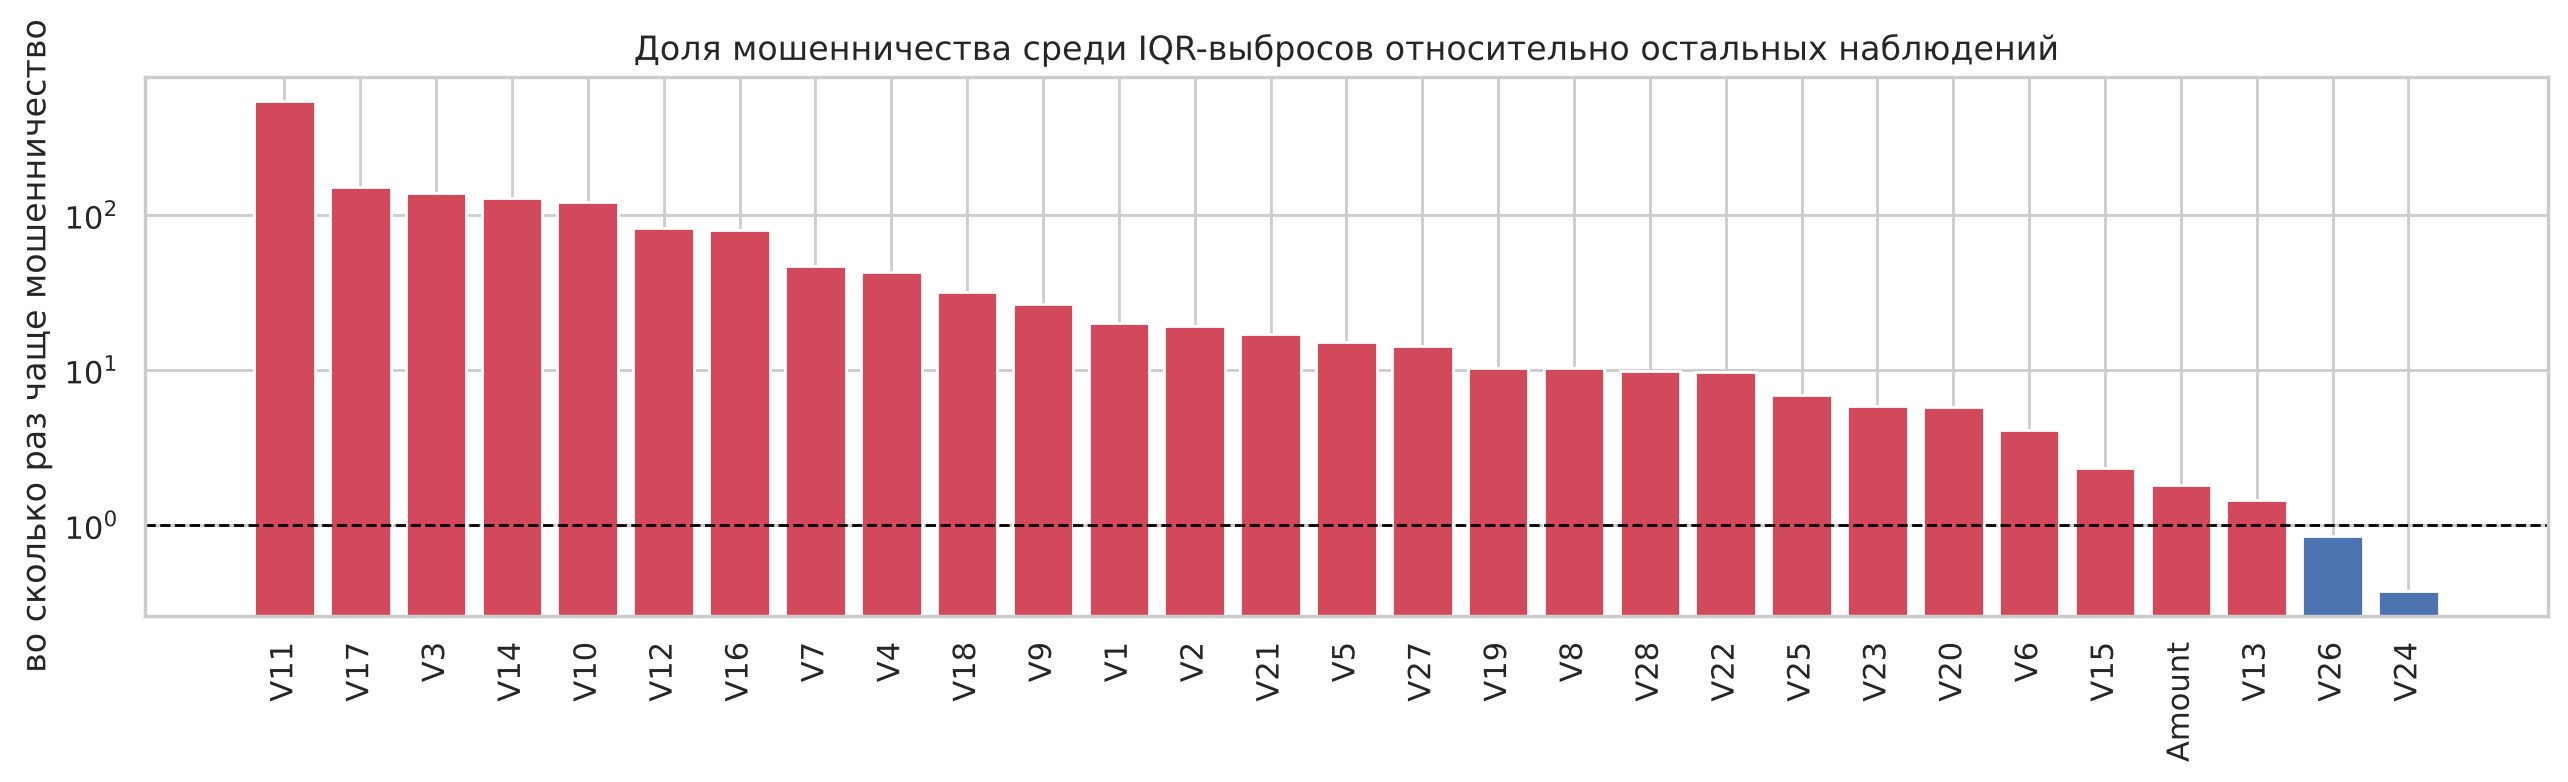

In [15]:
fig, ax = plt.subplots(figsize=(13, 4))
o = out.sort_values('lift', ascending=False)
ax.bar(o.index, o['lift'], color=np.where(o['lift'] > 1, PAL[1], PAL[0]))
ax.axhline(1, color='black', lw=1, ls='--')
ax.set_yscale('log')
ax.set_ylabel('во сколько раз чаще мошенничество')
ax.set_title('Доля мошенничества среди IQR-выбросов относительно остальных наблюдений')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

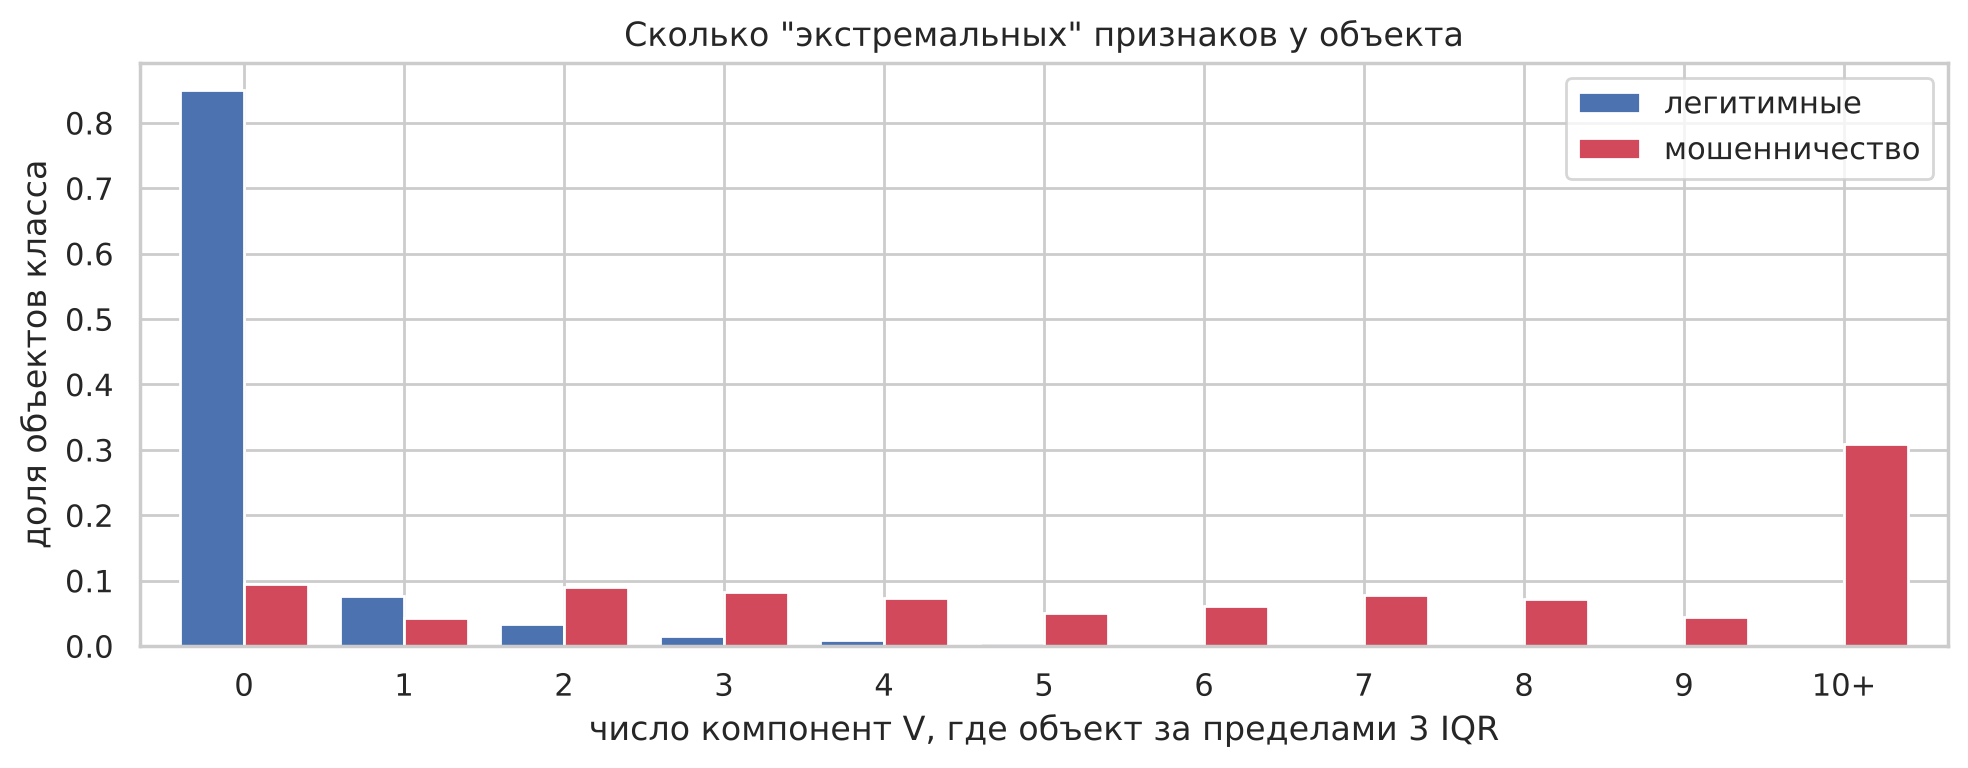

Медиана числа экстремальных признаков по классам: {0: 0.0, 1: 7.0}


In [16]:
extreme = pd.concat([iqr_mask(df[c], k=3) for c in V], axis=1).sum(axis=1)
df['n_extreme'] = extreme
tab = pd.crosstab(extreme.clip(upper=10), df['Class'], normalize='columns')
tab.index = [str(i) if i < 10 else '10+' for i in tab.index]

fig, ax = plt.subplots(figsize=(10, 4))
tab.plot.bar(ax=ax, color=[PAL[0], PAL[1]], width=0.8)
ax.set_xlabel('число компонент V, где объект за пределами 3 IQR')
ax.set_ylabel('доля объектов класса')
ax.legend(['легитимные', 'мошенничество'])
ax.set_title('Сколько "экстремальных" признаков у объекта')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print('Медиана числа экстремальных признаков по классам:', df.groupby('Class')['n_extreme'].median().to_dict())

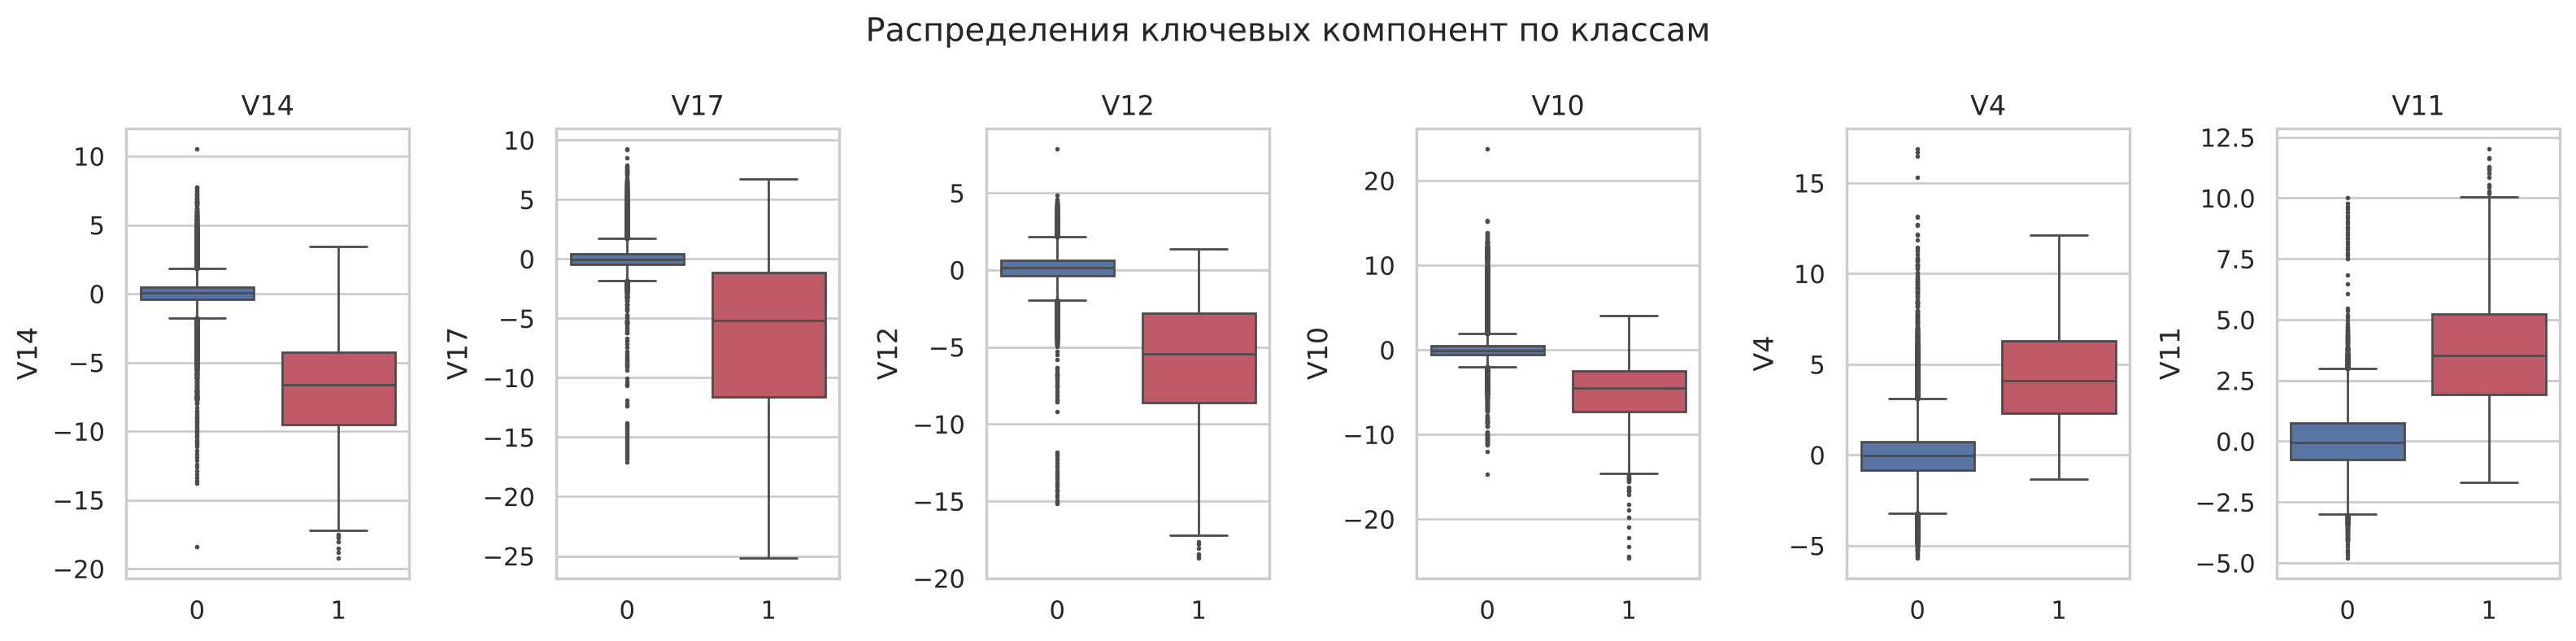

In [17]:
top_box = ['V14', 'V17', 'V12', 'V10', 'V4', 'V11']
fig, axes = plt.subplots(1, len(top_box), figsize=(16, 4))
for ax, c in zip(axes, top_box):
    sns.boxplot(data=df, x='Class', y=c, hue='Class', palette=PAL, legend=False, ax=ax, fliersize=1)
    ax.set_title(c)
    ax.set_xlabel('')
plt.suptitle('Распределения ключевых компонент по классам')
plt.tight_layout()
plt.show()

Что получилось с выбросами:
- у большинства компонент эксцесс сильно больше 0, а у `V28`, `V7`, `V27`, `V5` он вообще в сотнях, то есть хвосты очень тяжелые
- почти для всех компонент среди выбросов мошенничество встречается в десятки раз чаще, чем среди обычных точек
- у типичной мошеннической операции экстремальные значения сразу в нескольких компонентах (медиана 7), а у нормальной обычно ни в одной

Получается, что выбросы здесь во многом и есть то, что мы ищем. Если их удалить, из train пропадет большая часть класса 1, поэтому выбросы оставляем. Деревьям (XGBoost, Isolation Forest) масштаб не важен, а для One-Class SVM, LOF и логистической регрессии будем использовать `RobustScaler` или квантильное преобразование, `Amount` берем через `log1p`. Количество экстремальных компонент `n_extreme` тоже можно попробовать как отдельный признак.

## 6. Признаки по отдельности и связь с целевой переменной

### 6.1. Время

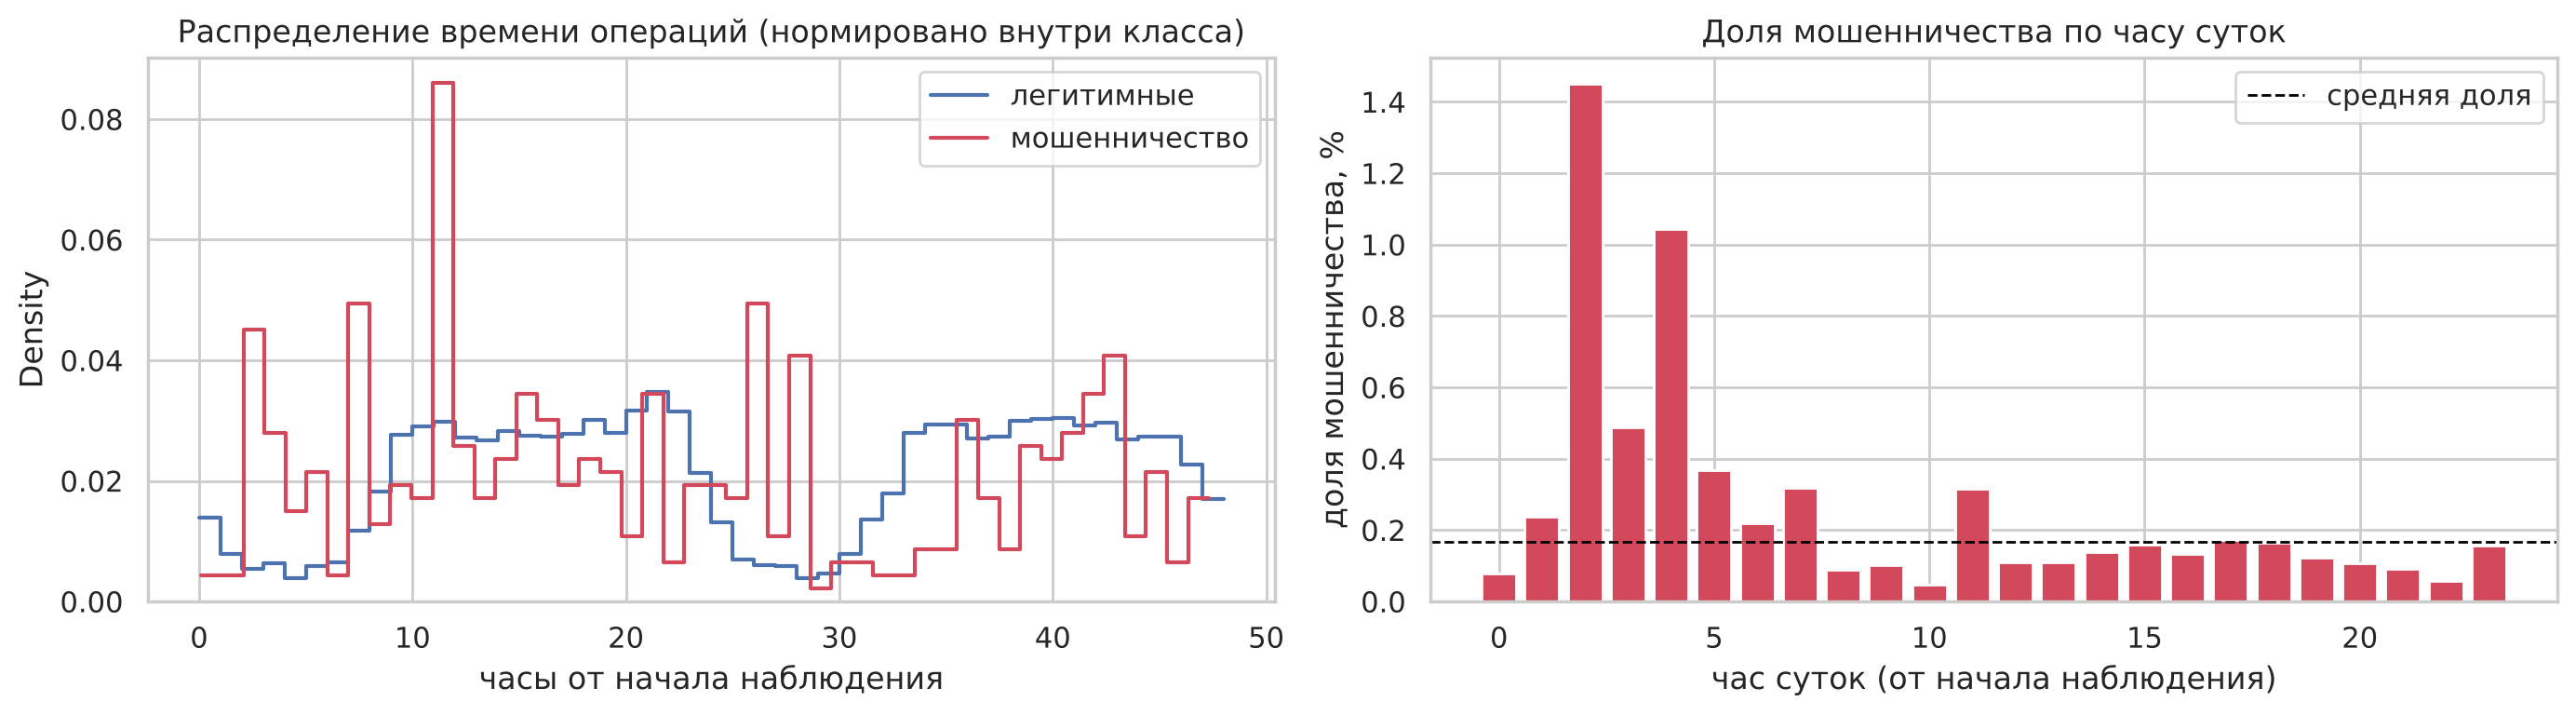

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for cls in [0, 1]:
    sns.histplot(df.loc[df['Class'] == cls, 'Time'] / 3600, bins=48, stat='density', element='step',
                 fill=False, color=PAL[cls], ax=axes[0], label=['легитимные', 'мошенничество'][cls])
axes[0].set_xlabel('часы от начала наблюдения')
axes[0].set_title('Распределение времени операций (нормировано внутри класса)')
axes[0].legend()

hr = df.groupby('hour')['Class'].agg(['mean', 'size'])
axes[1].bar(hr.index, hr['mean'] * 100, color=PAL[1])
axes[1].axhline(df['Class'].mean() * 100, color='black', ls='--', lw=1, label='средняя доля')
axes[1].set_xlabel('час суток (от начала наблюдения)')
axes[1].set_ylabel('доля мошенничества, %')
axes[1].set_title('Доля мошенничества по часу суток')
axes[1].legend()
plt.tight_layout()
plt.show()

У нормальных операций есть явный суточный цикл: ночью (примерно часы 1–6 от начала записи) их в 4–5 раз меньше. Мошеннические операции идут более равномерно, поэтому ночью доля мошенничества в разы выше средней, в час 2 это около 1.5% при среднем 0.17%.

Сам `Time` в модель брать нельзя, это просто секунды от начала выгрузки, и на новые данные он не переносится. Лучше взять час суток. Правда, мы не знаем, во сколько началась запись, так что `hour` это час относительно первой транзакции, а не настоящее местное время. Но для суточного цикла этого хватает.

### 6.2. Сумма операции

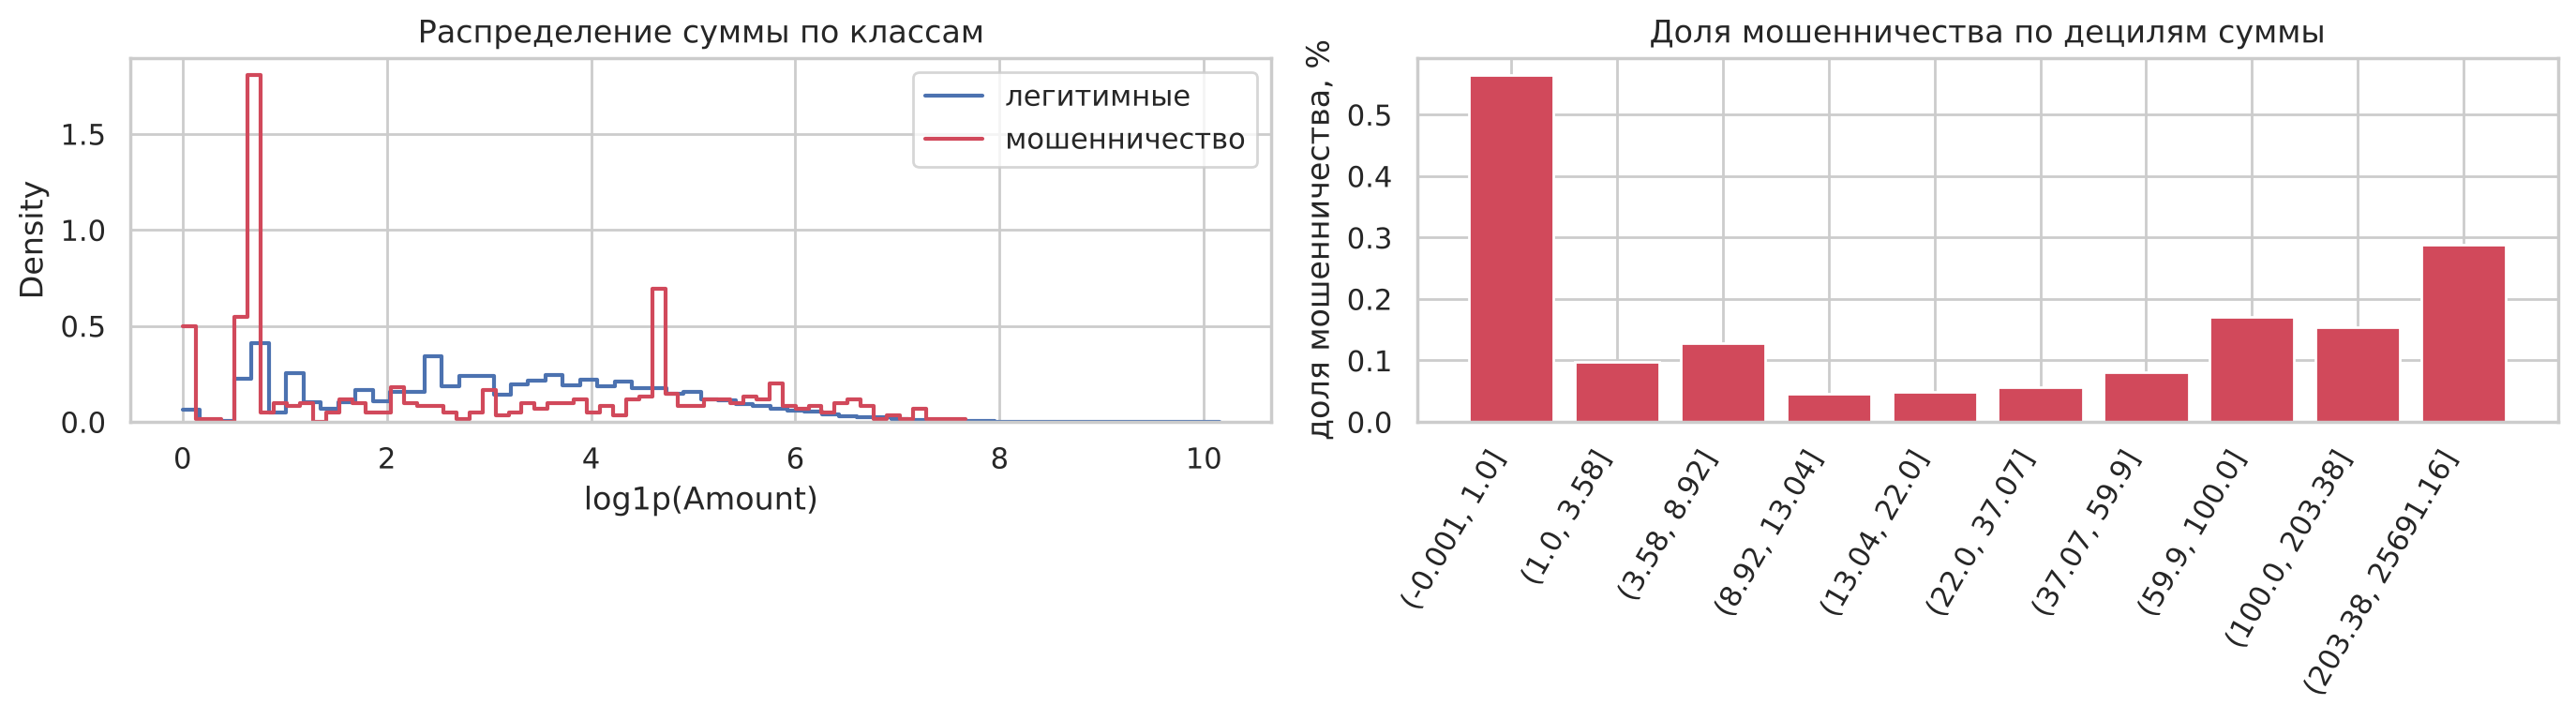

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87
KS-статистика: 0.265 p-value: 7.446283420073024e-30


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for cls in [0, 1]:
    sns.histplot(df.loc[df['Class'] == cls, 'amount_log'], bins=60, stat='density', element='step', fill=False,
                 color=PAL[cls], ax=axes[0], label=['легитимные', 'мошенничество'][cls])
axes[0].set_xlabel('log1p(Amount)')
axes[0].legend()
axes[0].set_title('Распределение суммы по классам')

bins = pd.qcut(df['Amount'], 10, duplicates='drop')
rate = df.groupby(bins, observed=True)['Class'].mean() * 100
axes[1].bar(range(len(rate)), rate.values, color=PAL[1])
axes[1].set_xticks(range(len(rate)))
axes[1].set_xticklabels([str(i) for i in rate.index], rotation=60, ha='right')
axes[1].set_ylabel('доля мошенничества, %')
axes[1].set_title('Доля мошенничества по децилям суммы')
plt.tight_layout()
plt.show()

print(df.groupby('Class')['Amount'].describe().round(2))
ks = stats.ks_2samp(df.loc[df['Class'] == 1, 'Amount'], df.loc[df['Class'] == 0, 'Amount'])
print('KS-статистика:', round(ks.statistic, 3), 'p-value:', ks.pvalue)

У мошенничества распределение суммы двугорбое: много совсем маленьких сумм (четверть меньше 1, похоже на проверку карты) и заметная часть крупных. Доля мошенничества зависит от суммы немонотонно: она высокая на самых маленьких суммах, потом падает и снова растет на больших. Линейная модель на сыром `Amount` такое не поймает, а деревья поймают.

Интересно, что максимальная мошенническая сумма всего 2125.87, а у нормальных операций есть суммы до 25 691, то есть самые крупные операции в датасете не мошеннические.

### 6.3. Компоненты V1–V28

In [20]:
pos = df['Class'] == 1
rows = []
for c in V + ['amount_log', 'hour', 'n_extreme']:
    auc = roc_auc_score(df['Class'], df[c])
    ks = stats.ks_2samp(df.loc[pos, c], df.loc[~pos, c]).statistic
    d = (df.loc[pos, c].mean() - df.loc[~pos, c].mean()) / df[c].std()
    rows.append({'feature': c, 'roc_auc_1d': max(auc, 1 - auc), 'direction': '+' if auc >= 0.5 else '-',
                 'pr_auc_1d': average_precision_score(df['Class'], df[c] if auc >= 0.5 else -df[c]),
                 'ks': ks, 'std_mean_diff': d})
sep = pd.DataFrame(rows).set_index('feature').sort_values('ks', ascending=False)
sep.round(3)

,roc_auc_1d,direction,pr_auc_1d,ks,std_mean_diff
feature,,,,,
V14,0.947,-,0.605,0.838,-7.191
V10,0.911,-,0.539,0.797,-5.073
n_extreme,0.929,+,0.217,0.789,6.316
V12,0.934,-,0.561,0.777,-6.145
V4,0.936,+,0.193,0.761,3.170
V11,0.915,+,0.476,0.747,3.654
V17,0.800,-,0.601,0.736,-7.685
V3,0.909,-,0.207,0.695,-4.469
V16,0.841,-,0.454,0.678,-4.588


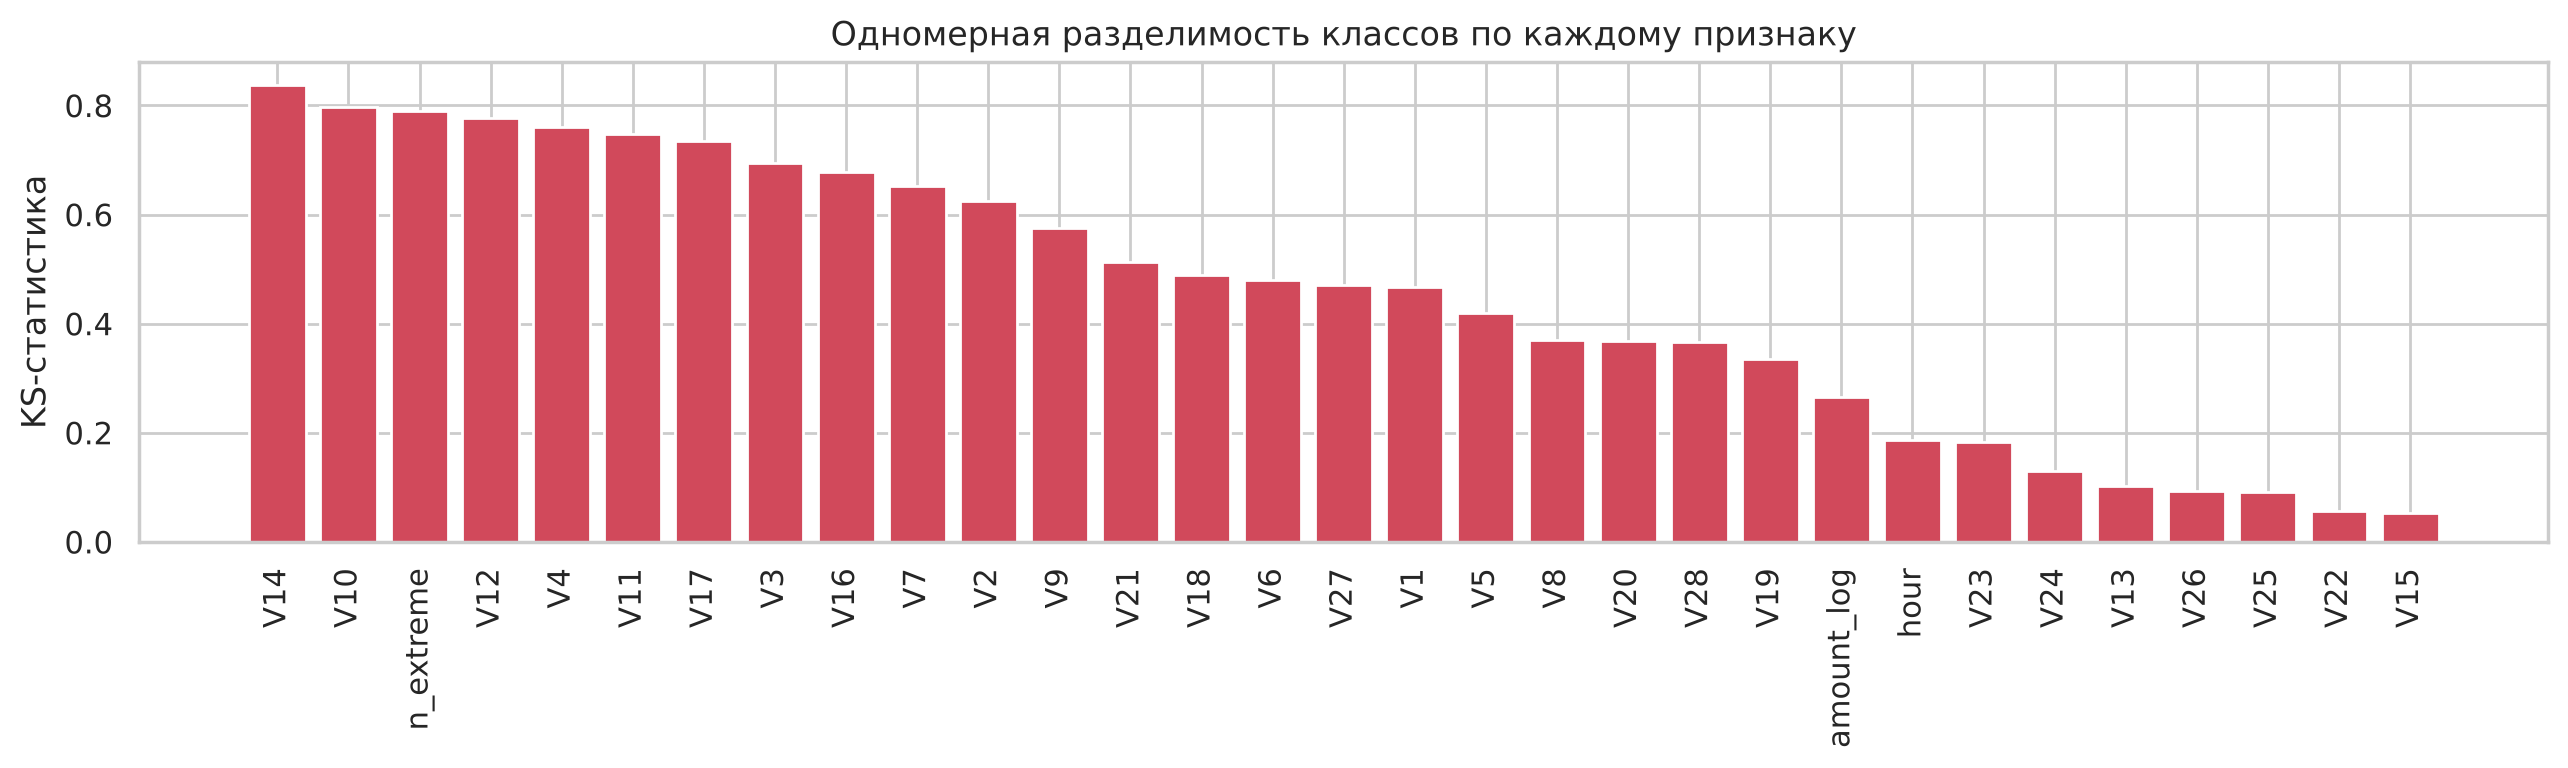

In [21]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(sep.index, sep['ks'], color=PAL[1])
ax.set_ylabel('KS-статистика')
ax.set_title('Одномерная разделимость классов по каждому признаку')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

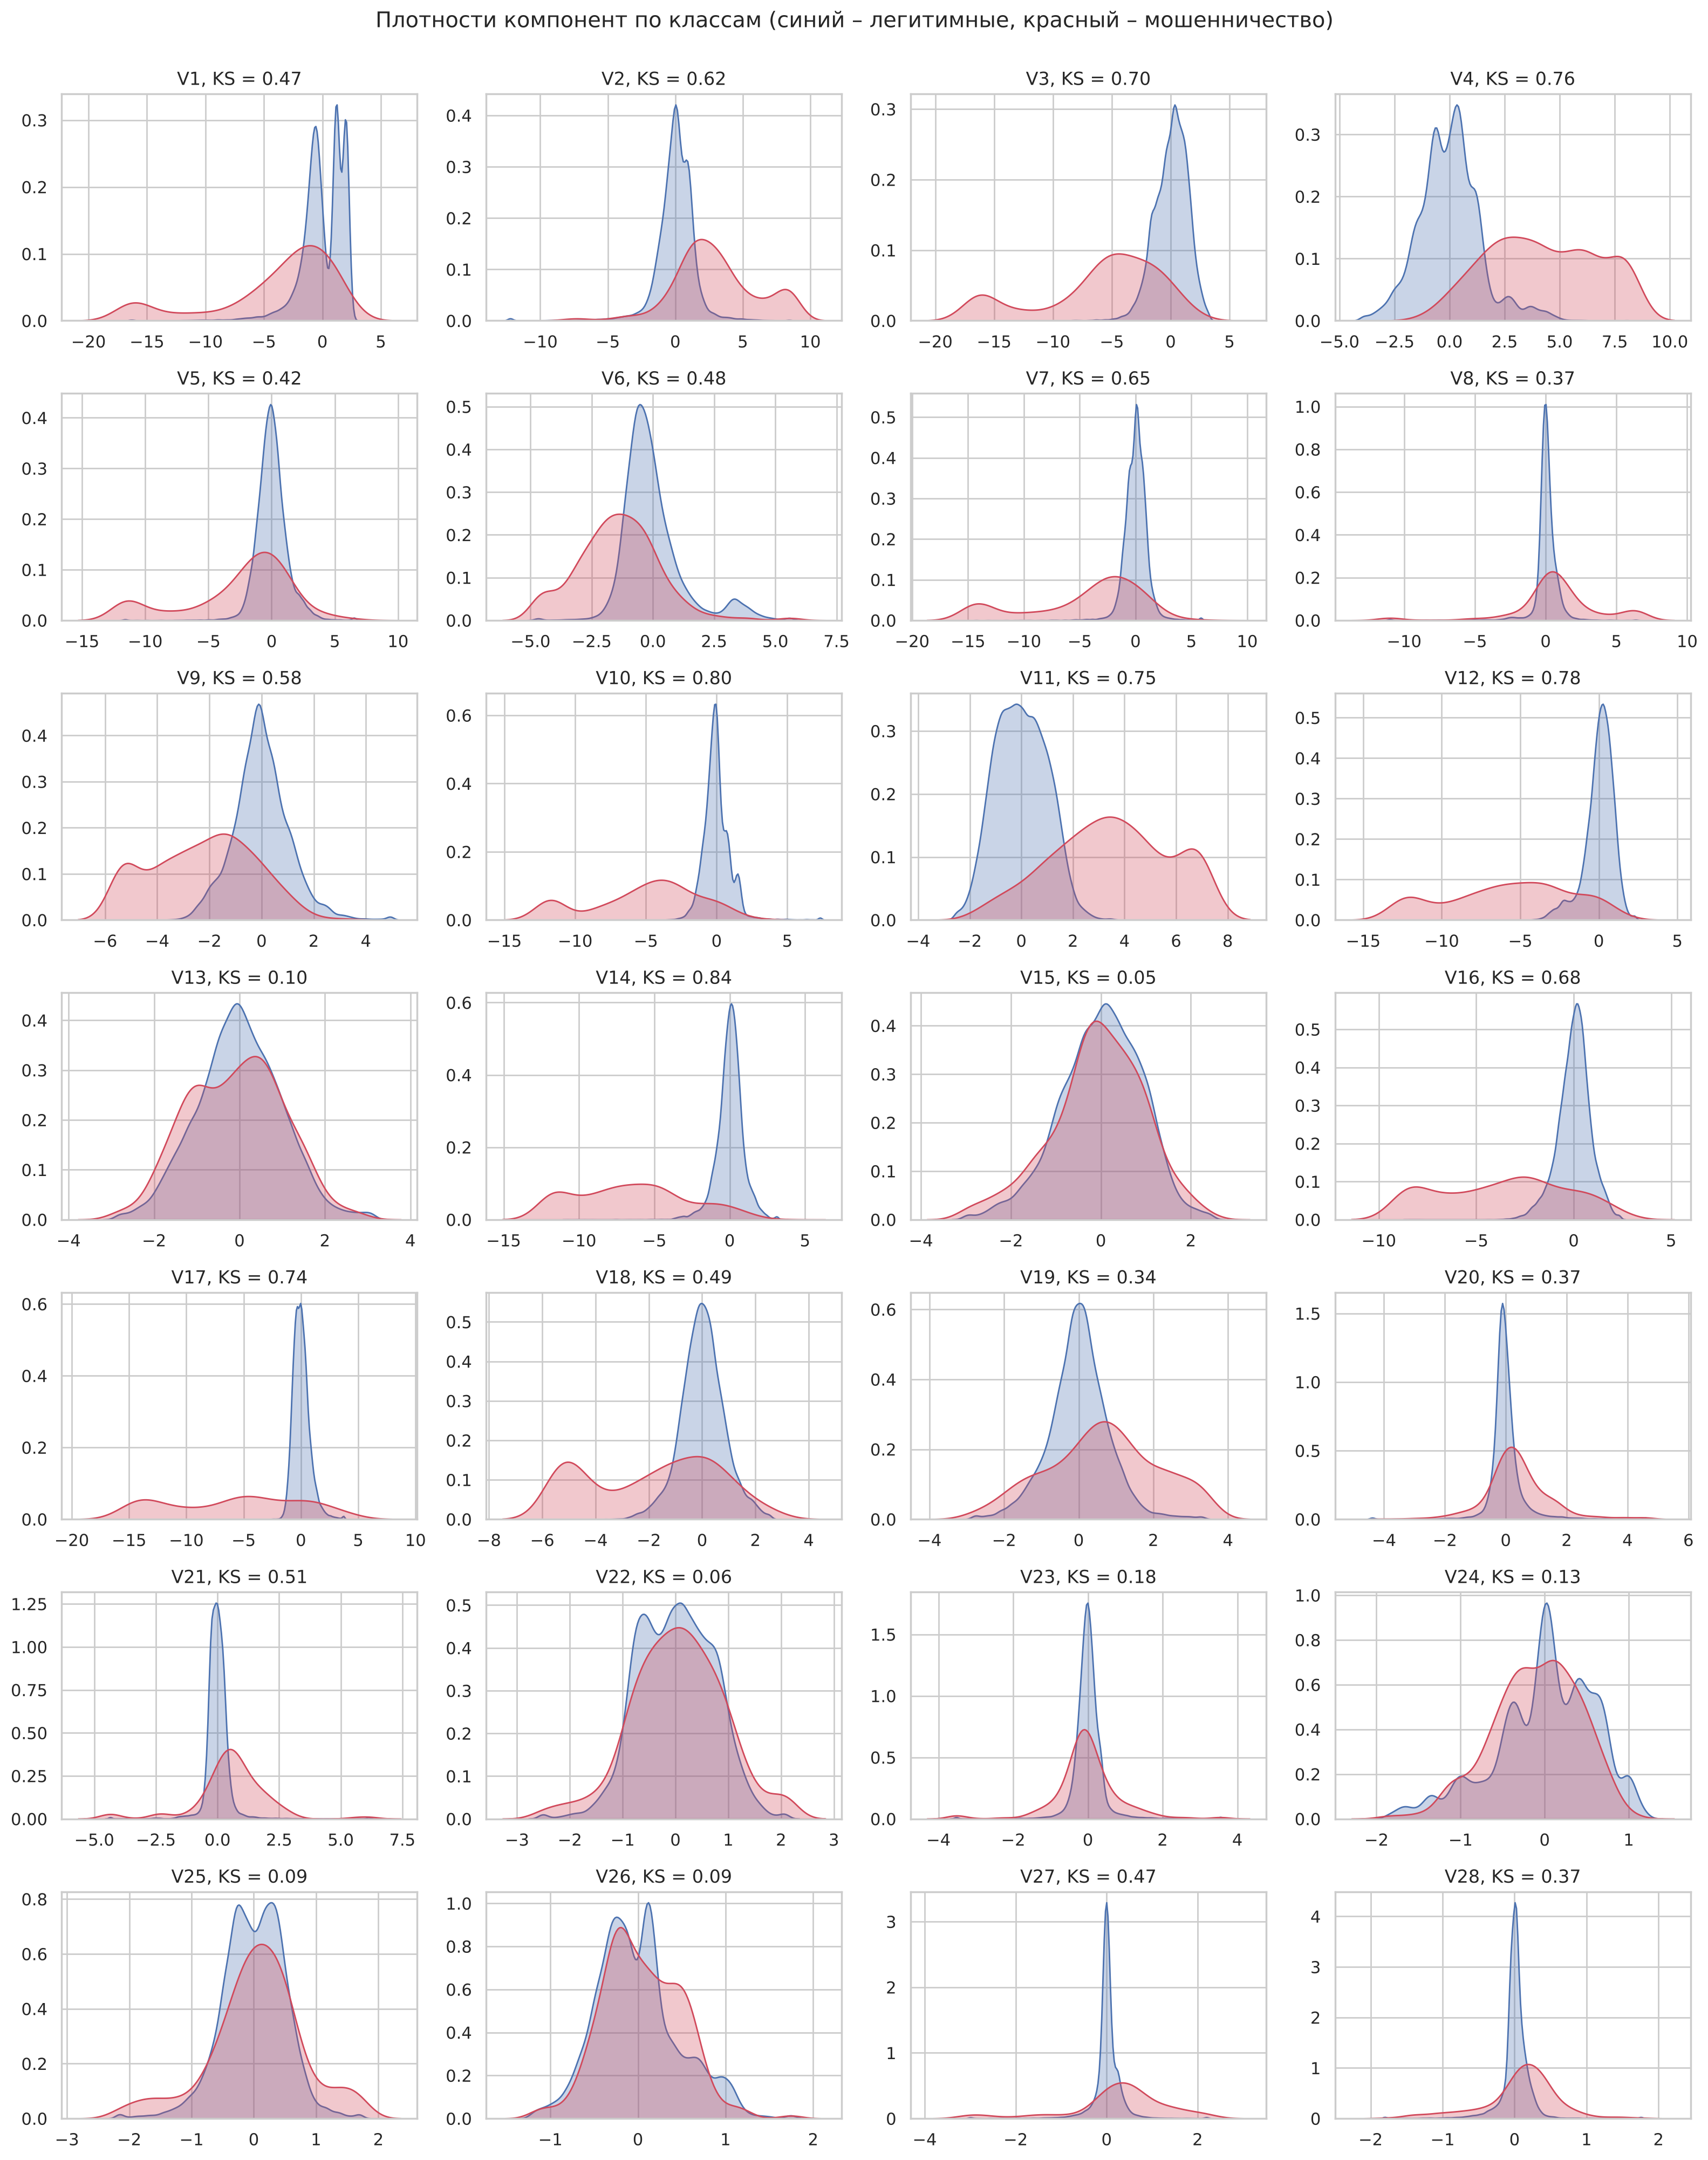

In [22]:
sample = pd.concat([df[~pos].sample(30000, random_state=RS), df[pos]])
fig, axes = plt.subplots(7, 4, figsize=(16, 20))
for ax, c in zip(axes.ravel(), V):
    lo, hi = sample[c].quantile([0.002, 0.998])
    for cls in [0, 1]:
        sns.kdeplot(sample.loc[sample['Class'] == cls, c].clip(lo, hi), ax=ax, color=PAL[cls],
                    fill=True, alpha=0.3, common_norm=False, warn_singular=False)
    ax.set_title(f"{c}, KS = {sep.loc[c, 'ks']:.2f}")
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.suptitle('Плотности компонент по классам (синий – легитимные, красный – мошенничество)', y=1.0)
plt.tight_layout()
plt.show()

- Лучше всего классы разделяются по `V14`, `V12`, `V10`, `V17`, `V4`, `V11`, `V3`, `V16`. У мошенничества эти распределения сдвинуты и сильно шире. Одна `V14` дает ROC-AUC около 0.95.
- `V13`, `V15`, `V22`–`V26` почти не отличаются между классами. Это нормально, PCA строится без таргета, и полезный сигнал оказывается только в части компонент.
- Даже у лучшего признака PR-AUC (0.6) сильно ниже ROC-AUC (0.95). Хорошо видно, почему при дисбалансе ROC-AUC слишком оптимистична.

## 7. Корреляции

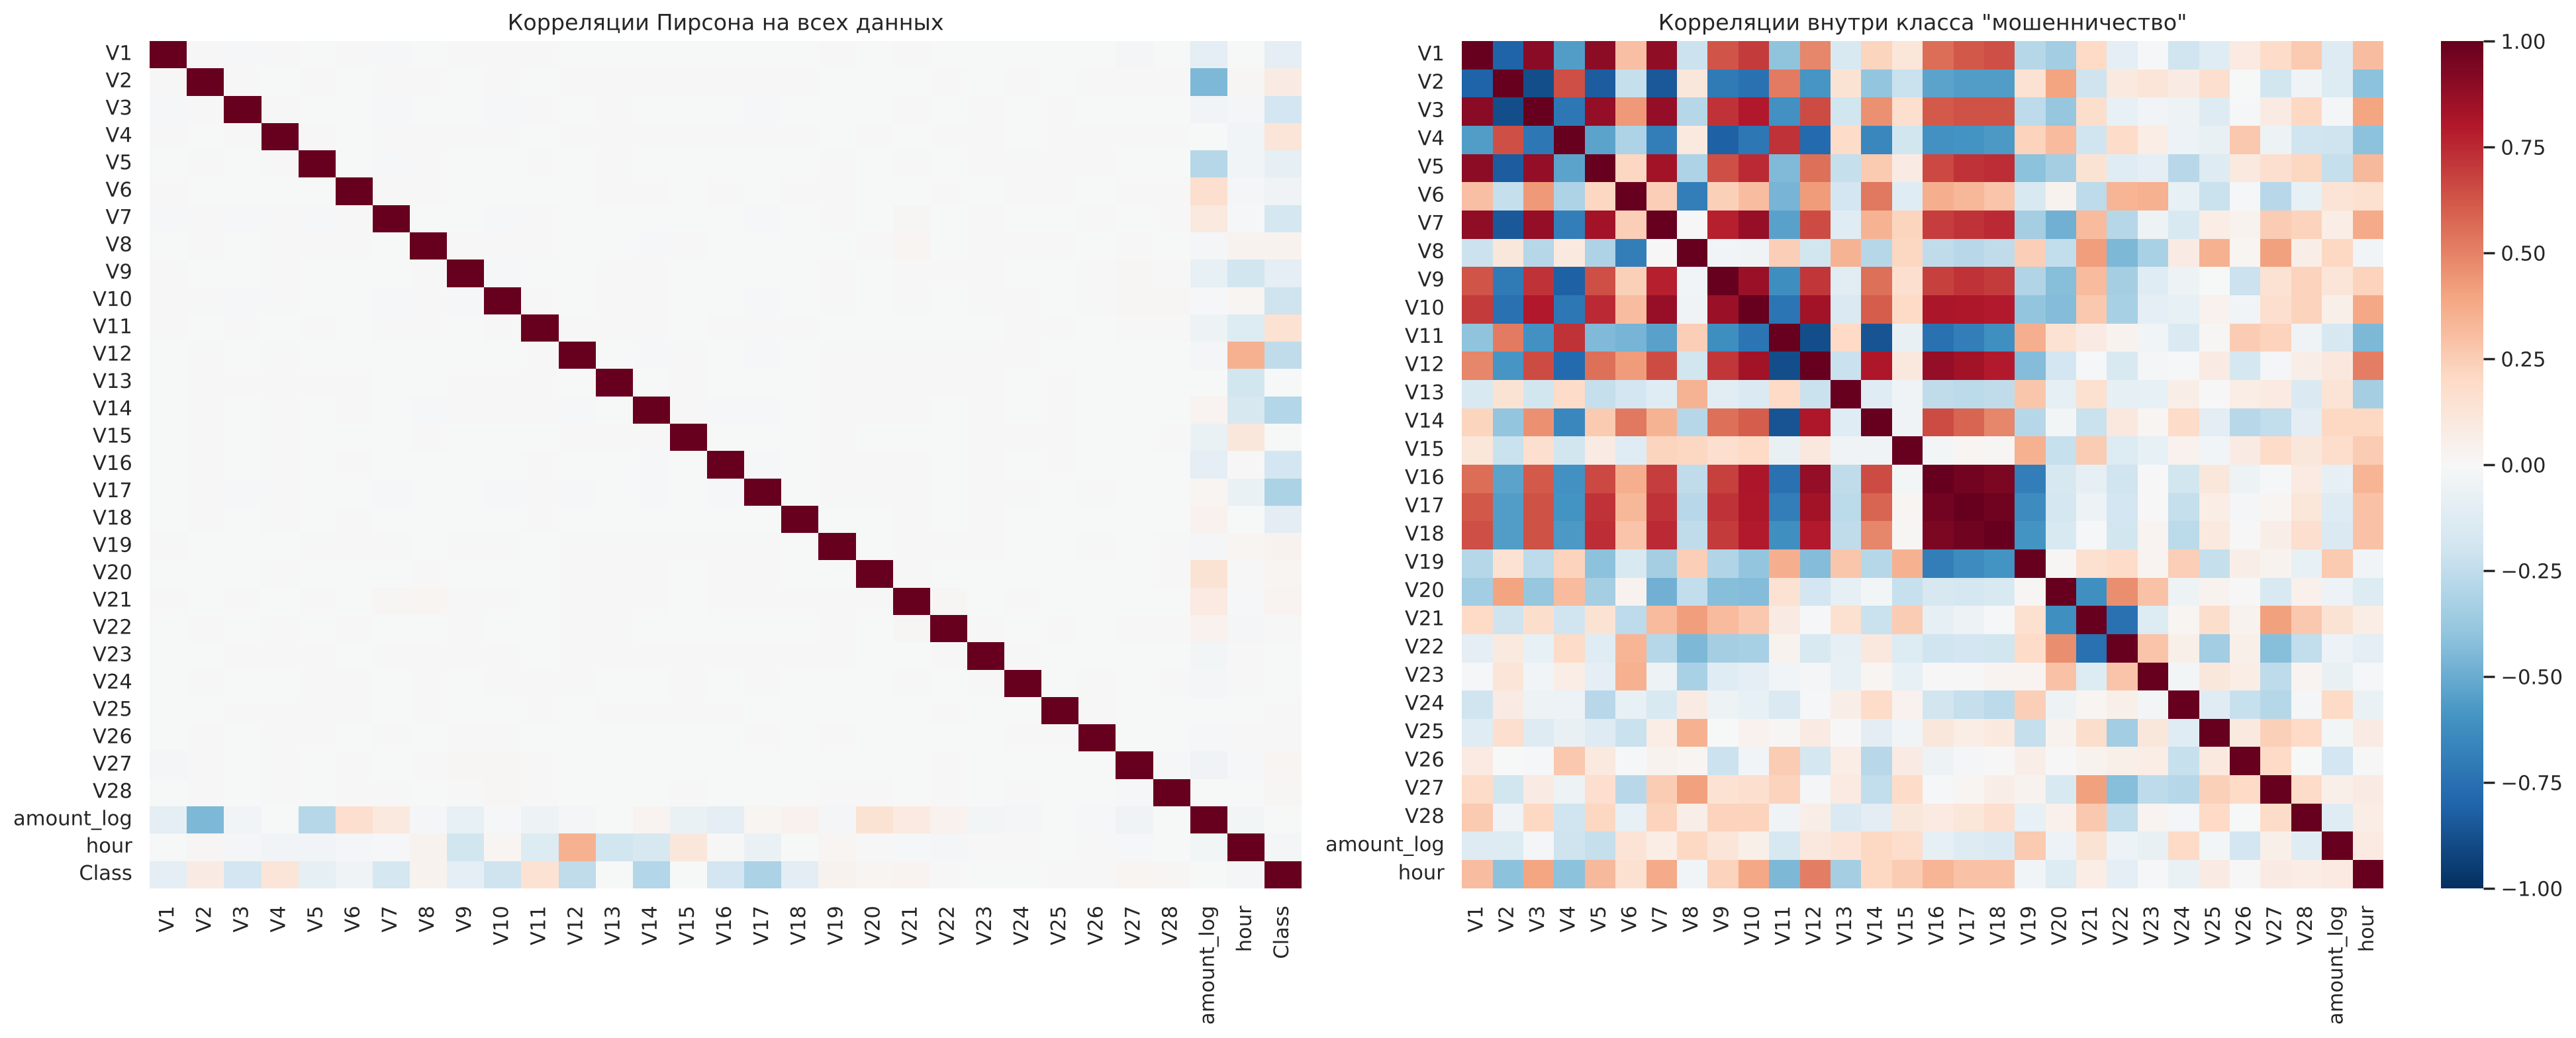

In [23]:
cols = V + ['amount_log', 'hour', 'Class']
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(df[cols].corr(), cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('Корреляции Пирсона на всех данных')
sns.heatmap(df.loc[pos, cols[:-1]].corr(), cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Корреляции внутри класса "мошенничество"')
plt.tight_layout()
plt.show()

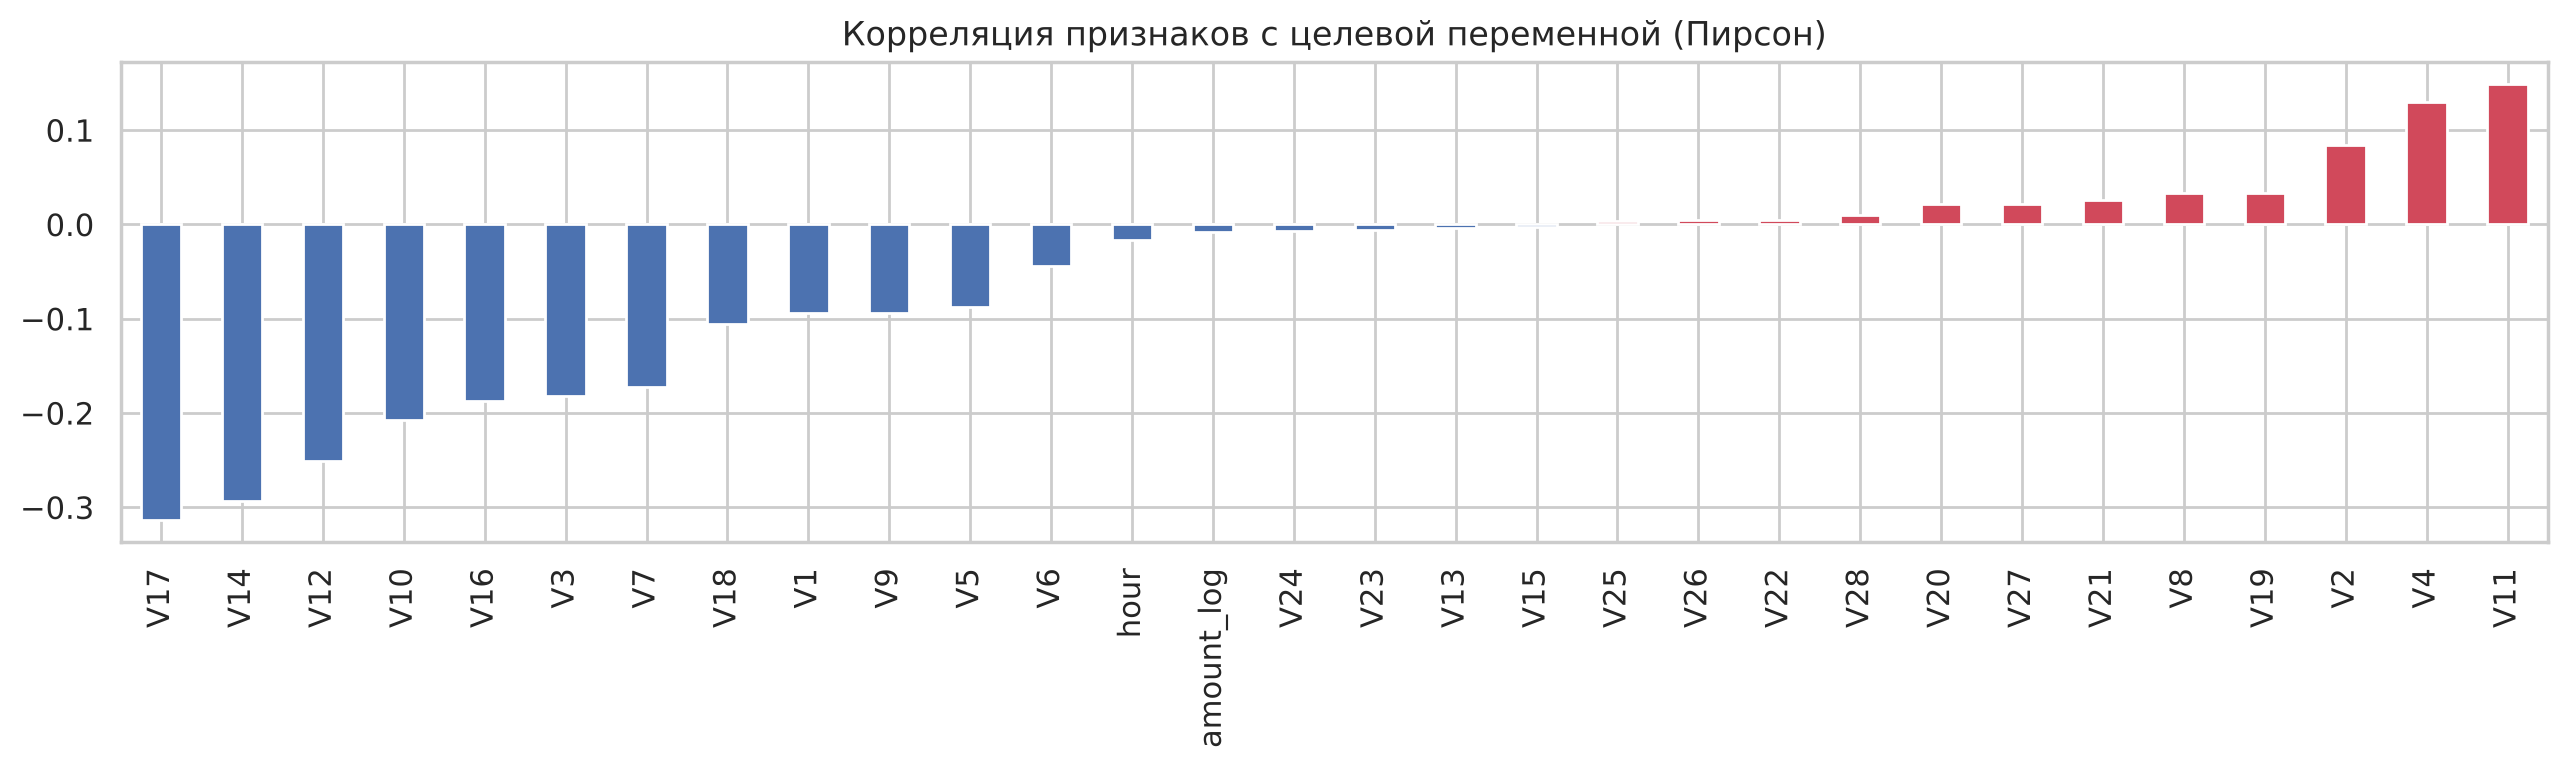

,V17,V14,V12,V10,V16,V3,V7,V18,V1,V9,V5,V6,hour,amount_log,V24,V23,V13,V15,V25,V26,V22,V28,V20,V27,V21,V8,V19,V2,V4,V11
pearson,-0.313,-0.293,-0.251,-0.207,-0.187,-0.182,-0.172,-0.105,-0.094,-0.094,-0.088,-0.044,-0.017,-0.008,-0.007,-0.006,-0.004,-0.003,0.003,0.004,0.005,0.010,0.021,0.022,0.026,0.033,0.034,0.085,0.129,0.149
spearman,-0.042,-0.063,-0.061,-0.058,-0.048,-0.058,-0.047,-0.033,-0.041,-0.048,-0.028,-0.038,-0.014,-0.008,-0.009,-0.006,-0.003,-0.002,0.005,0.005,0.002,0.021,0.022,0.029,0.034,0.023,0.022,0.049,0.062,0.059


In [24]:
corr_t = pd.DataFrame({
    'pearson': df[cols].corr()['Class'].drop('Class'),
    'spearman': df[cols].corr(method='spearman')['Class'].drop('Class'),
}).sort_values('pearson')
fig, ax = plt.subplots(figsize=(13, 4))
corr_t['pearson'].plot.bar(ax=ax, color=np.where(corr_t['pearson'] > 0, PAL[1], PAL[0]))
ax.set_title('Корреляция признаков с целевой переменной (Пирсон)')
plt.tight_layout()
plt.show()
corr_t.round(3).T

- На всех данных компоненты между собой не коррелируют, так работает PCA. Заметная корреляция есть только у суммы с некоторыми компонентами (у `Amount` с `V2` около -0.53, с `V7` и `V5` около 0.4, с `V20` около 0.34). Сумму в PCA не включали, но исходные признаки, видимо, были с ней связаны.
- Если посмотреть только на мошенничество, картина другая: многие компоненты сильно коррелируют друг с другом, особенно `V1`–`V18` (средний модуль корреляции 0.52 против 0.26 у `V19`–`V28`). То есть мошеннические операции вытянуты вдоль своего направления в пространстве признаков. Это аргумент в пользу нелинейных моделей.
- Корреляции с таргетом небольшие, максимум около 0.3 по модулю. Это из-за дисбаланса: при таком редком классе point-biserial корреляция просто не может быть большой. Порядок признаков примерно тот же, что и по KS.

## 8. Попарные распределения

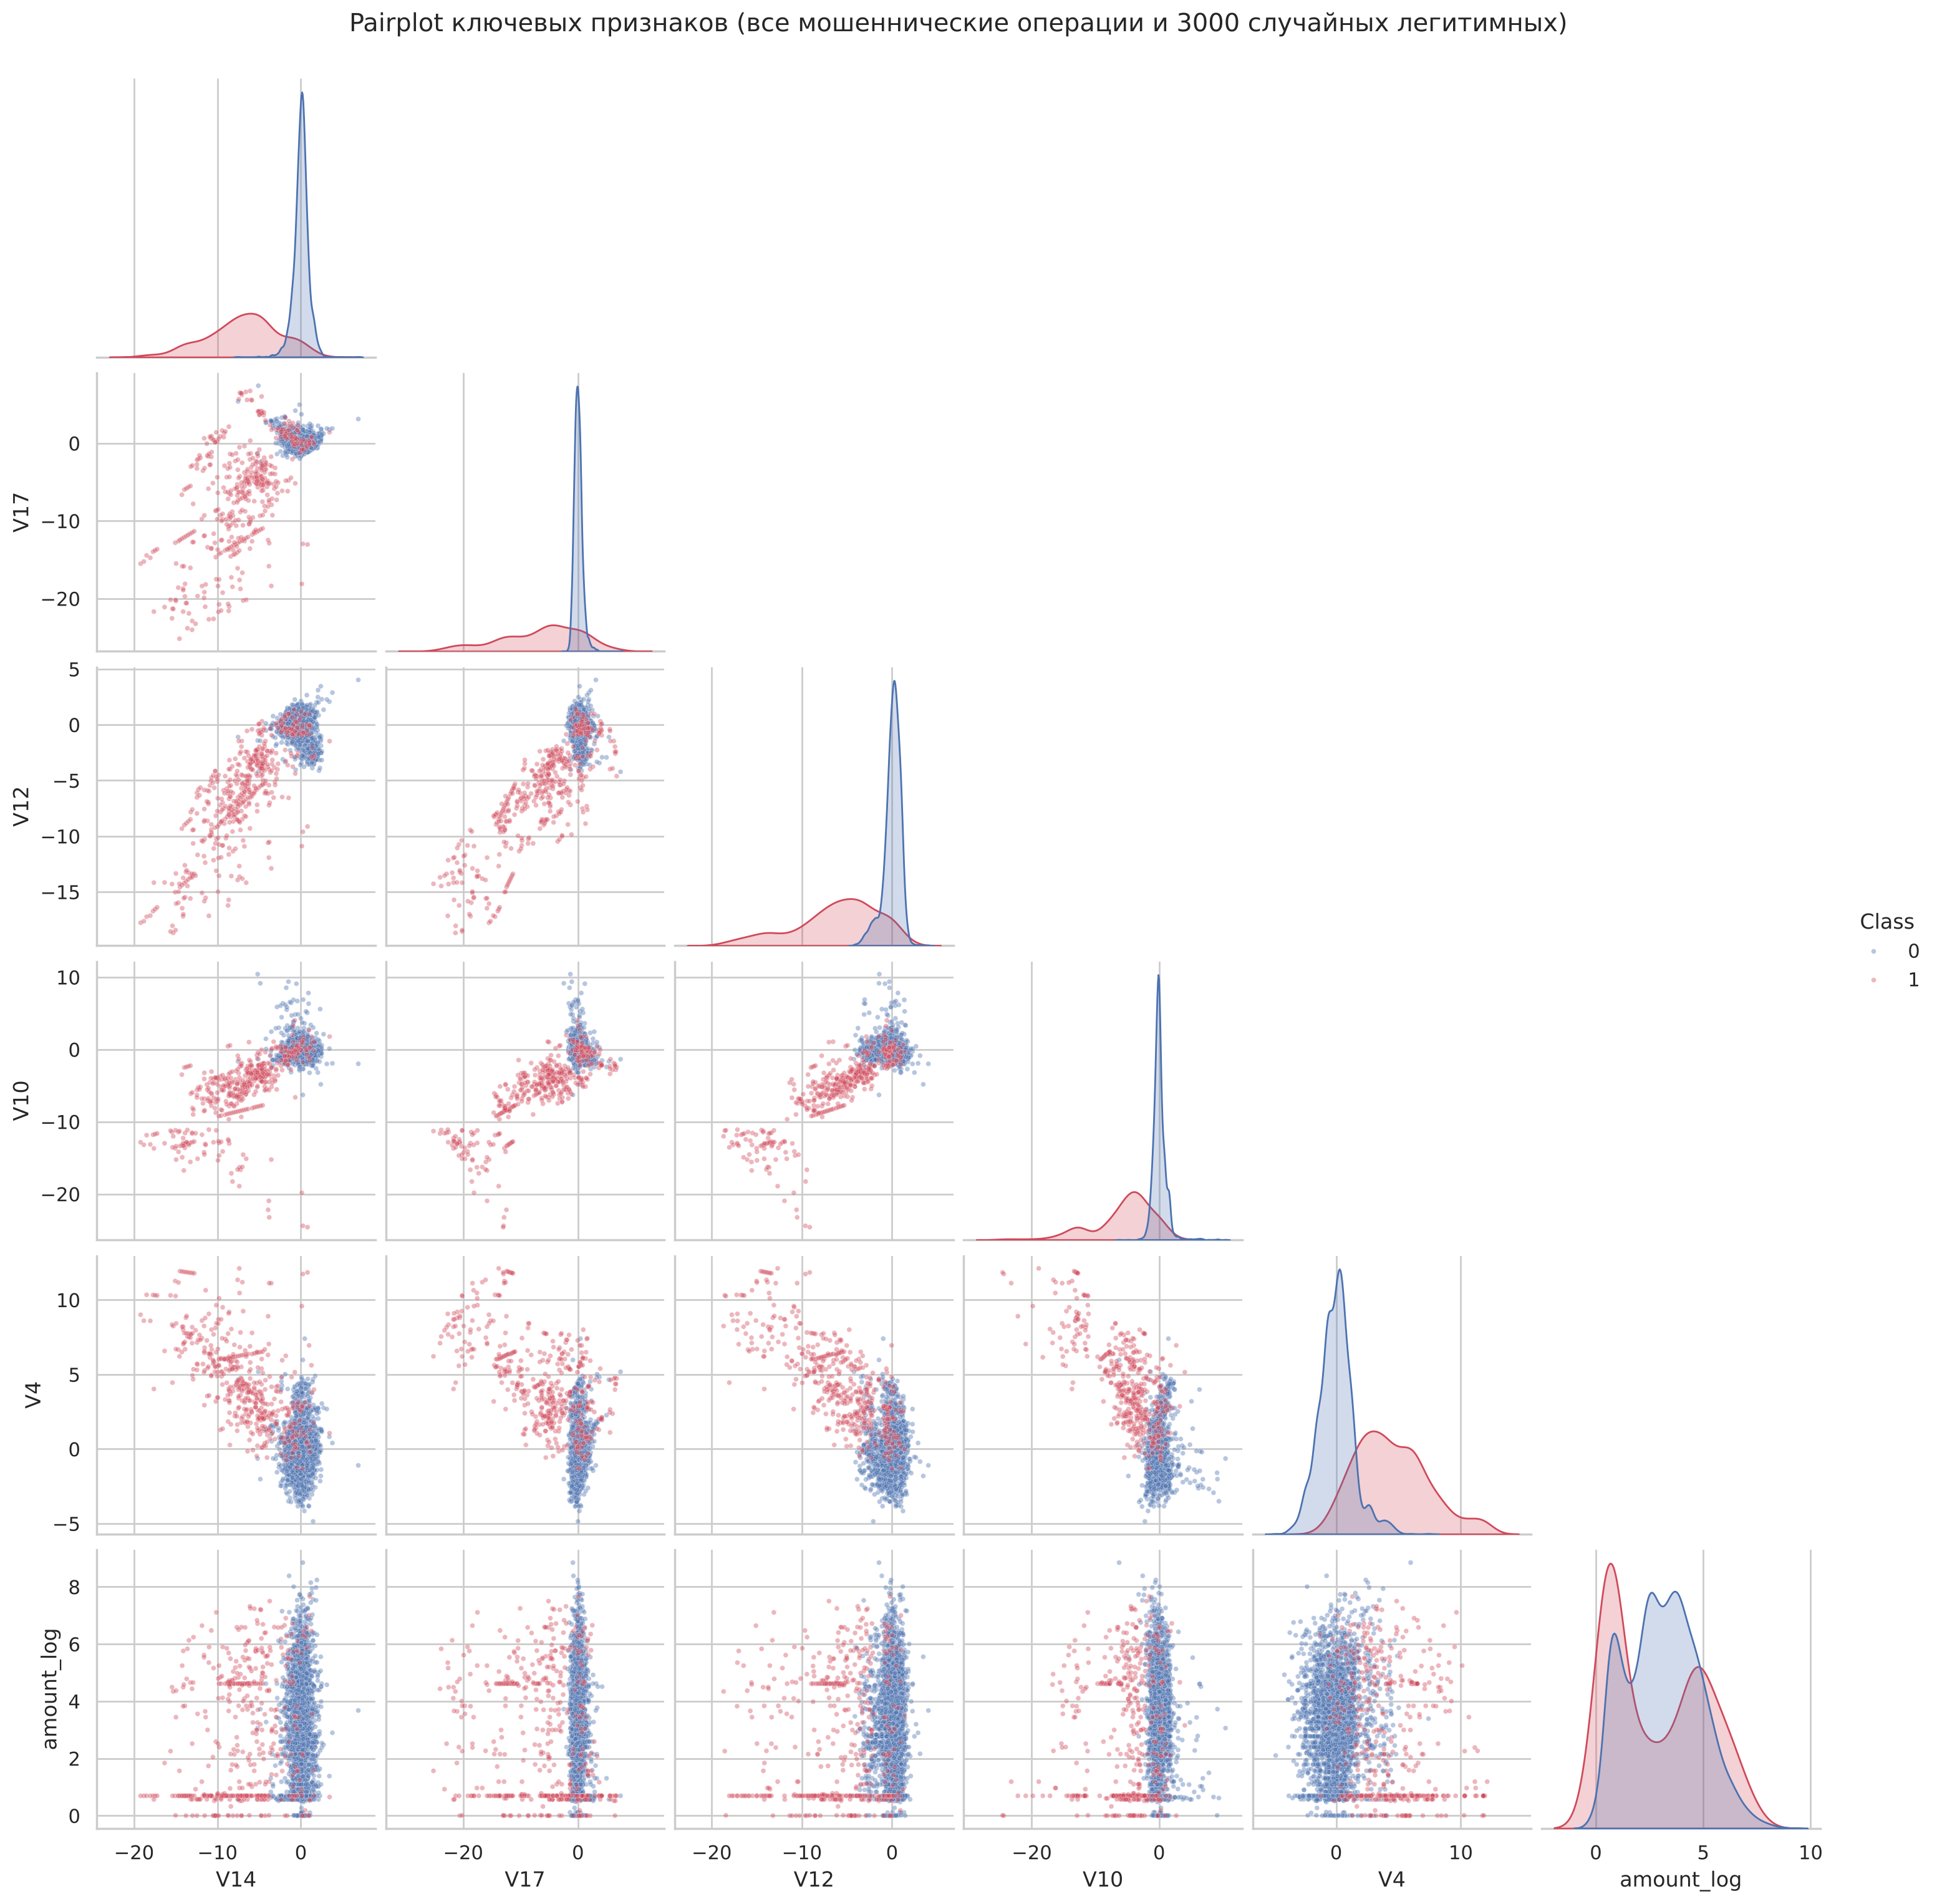

In [25]:
pp_cols = ['V14', 'V17', 'V12', 'V10', 'V4', 'amount_log']
pp = pd.concat([df[~pos].sample(3000, random_state=RS), df[pos]])[pp_cols + ['Class']]
g = sns.pairplot(pp, hue='Class', palette=PAL, plot_kws={'s': 8, 'alpha': 0.4}, diag_kws={'common_norm': False}, corner=True)
g.fig.suptitle('Pairplot ключевых признаков (все мошеннические операции и 3000 случайных легитимных)', y=1.02)
plt.show()

На pairplot видно, что мошеннические операции уходят "хвостами" от плотного облака нормальных, особенно в парах `V14`–`V17`, `V12`–`V14`, `V10`–`V14`. Но часть мошенничества лежит прямо внутри облака, и по этим признакам ее не отличить, скорее всего, именно эти операции модели будут пропускать. Надо помнить, что выборка для графика сбалансирована искусственно, на самом деле синих точек в 578 раз больше.

## 9. Сводные таблицы

In [26]:
df['amount_bin'] = pd.cut(df['Amount'], [-0.01, 0, 1, 10, 50, 200, 1000, np.inf],
                          labels=['0', '(0, 1]', '(1, 10]', '(10, 50]', '(50, 200]', '(200, 1000]', '>1000'])
df['day_part'] = pd.cut(df['hour'], [-1, 6, 11, 17, 23], labels=['ночь 0-6', 'утро 7-11', 'день 12-17', 'вечер 18-23'])
df.groupby('amount_bin', observed=True)['Class'].agg(n='size', n_fraud='sum', fraud_rate='mean').round(4)

,n,n_fraud,fraud_rate
amount_bin,,,
0,1808,25,0.0138
"(0, 1]",28523,146,0.0051
"(1, 10]",69490,67,0.0010
"(10, 50]",90327,55,0.0006
"(50, 200]",64808,98,0.0015
"(200, 1000]",25835,73,0.0028
>1000,2935,9,0.0031


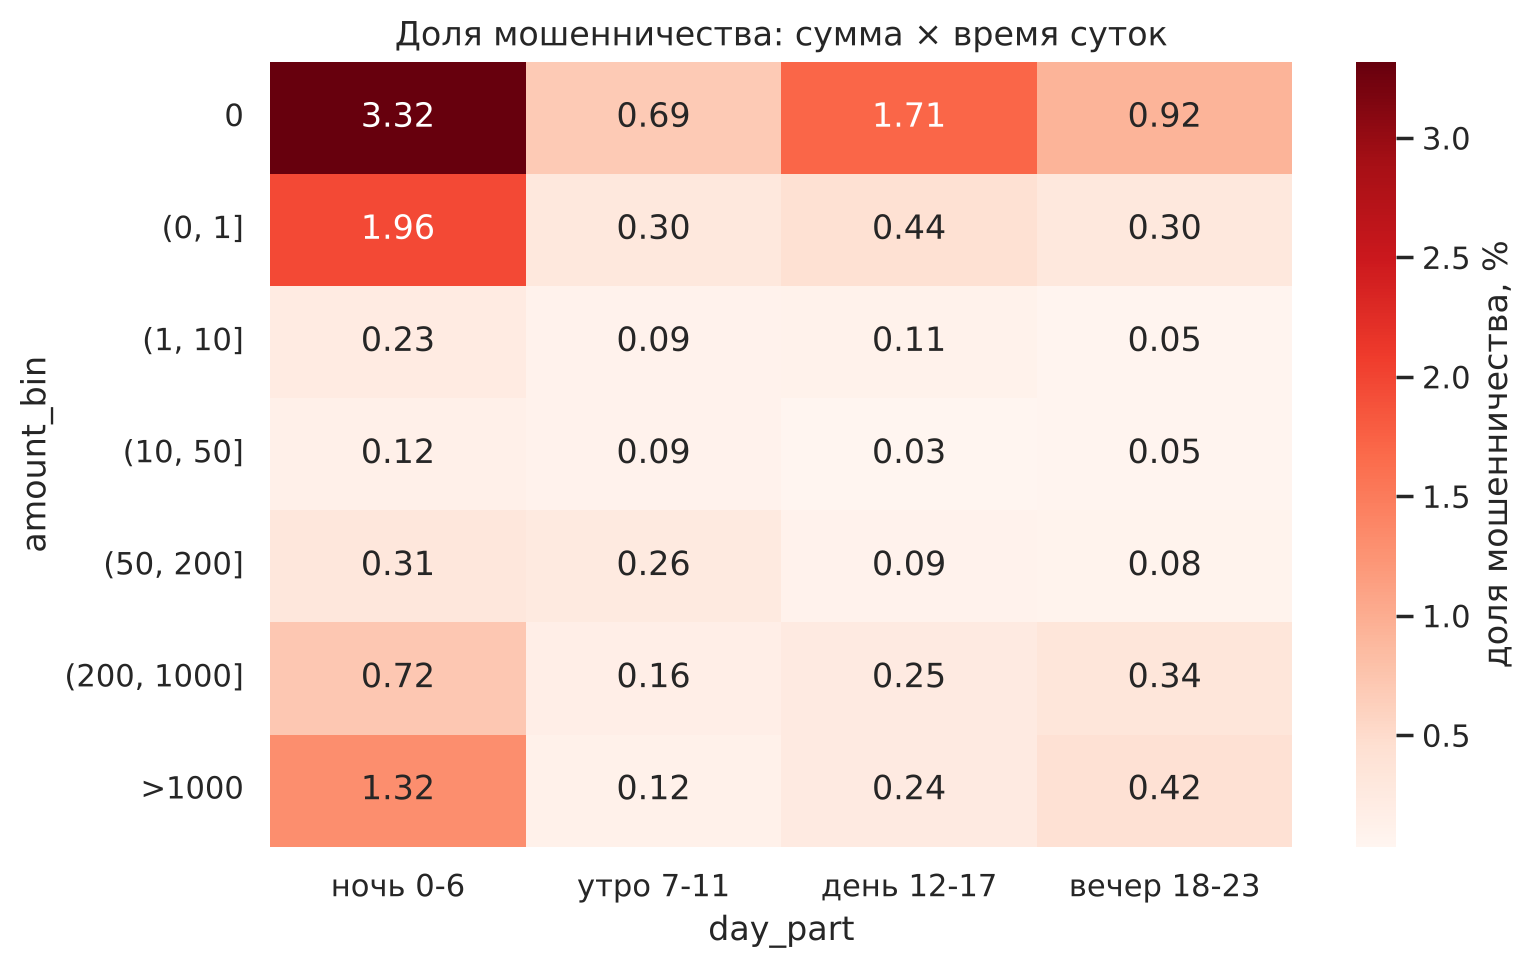

In [27]:
pv = pd.pivot_table(df, index='amount_bin', columns='day_part', values='Class', aggfunc='mean', observed=True) * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pv, annot=True, fmt='.2f', cmap='Reds', ax=ax, cbar_kws={'label': 'доля мошенничества, %'})
ax.set_title('Доля мошенничества: сумма × время суток')
plt.tight_layout()
plt.show()

In [28]:
pd.pivot_table(df, index='Class', values=['Amount', 'V14', 'V17', 'V12', 'n_extreme'],
               aggfunc=['mean', 'median']).round(2)

mean                             median                            
       Amount   V12   V14   V17 n_extreme Amount   V12   V14   V17 n_extreme
Class                                                                       
0       88.41  0.01  0.01  0.01      0.33  22.00  0.14  0.05 -0.07       0.0
1      123.87 -6.10 -6.84 -6.46      7.74   9.82 -5.44 -6.59 -5.16       7.0

Если сумма маленькая и операция ночью, доля мошенничества получается на порядок выше средней (2–3% против 0.17%). Это пример того, что взаимодействия признаков важны, а деревья как раз такие правила и строят.

## 10. Типы аномальных наблюдений

В проекте мы сравниваем поиск аномалий и обучение с учителем, поэтому интересно, насколько мошенничество здесь вообще "аномальное" в геометрическом смысле. Обучим Isolation Forest без меток и посмотрим, как его скор связан с классом.

In [29]:
X_anom = df[V + ['amount_log']]
iso = IsolationForest(n_estimators=200, random_state=RS, n_jobs=-1).fit(X_anom)
df['iso_score'] = -iso.score_samples(X_anom)
print('ROC-AUC Isolation Forest без меток:', round(roc_auc_score(df['Class'], df['iso_score']), 4))
print('PR-AUC Isolation Forest без меток:', round(average_precision_score(df['Class'], df['iso_score']), 4))

ROC-AUC Isolation Forest без меток: 0.9502
PR-AUC Isolation Forest без меток: 0.1406


In [30]:
thr = df['iso_score'].quantile(0.99)
df['iso_top1'] = df['iso_score'] >= thr
anom_tab = pd.crosstab(df['iso_top1'], df['Class'], margins=True)
anom_tab.index = ['обычные (99%)', 'аномальные (top 1%)', 'всего']
anom_tab.columns = ['легитимные', 'мошенничество', 'всего']
anom_tab

,легитимные,мошенничество,всего
обычные (99%),280683,205,280888
аномальные (top 1%),2570,268,2838
всего,283253,473,283726


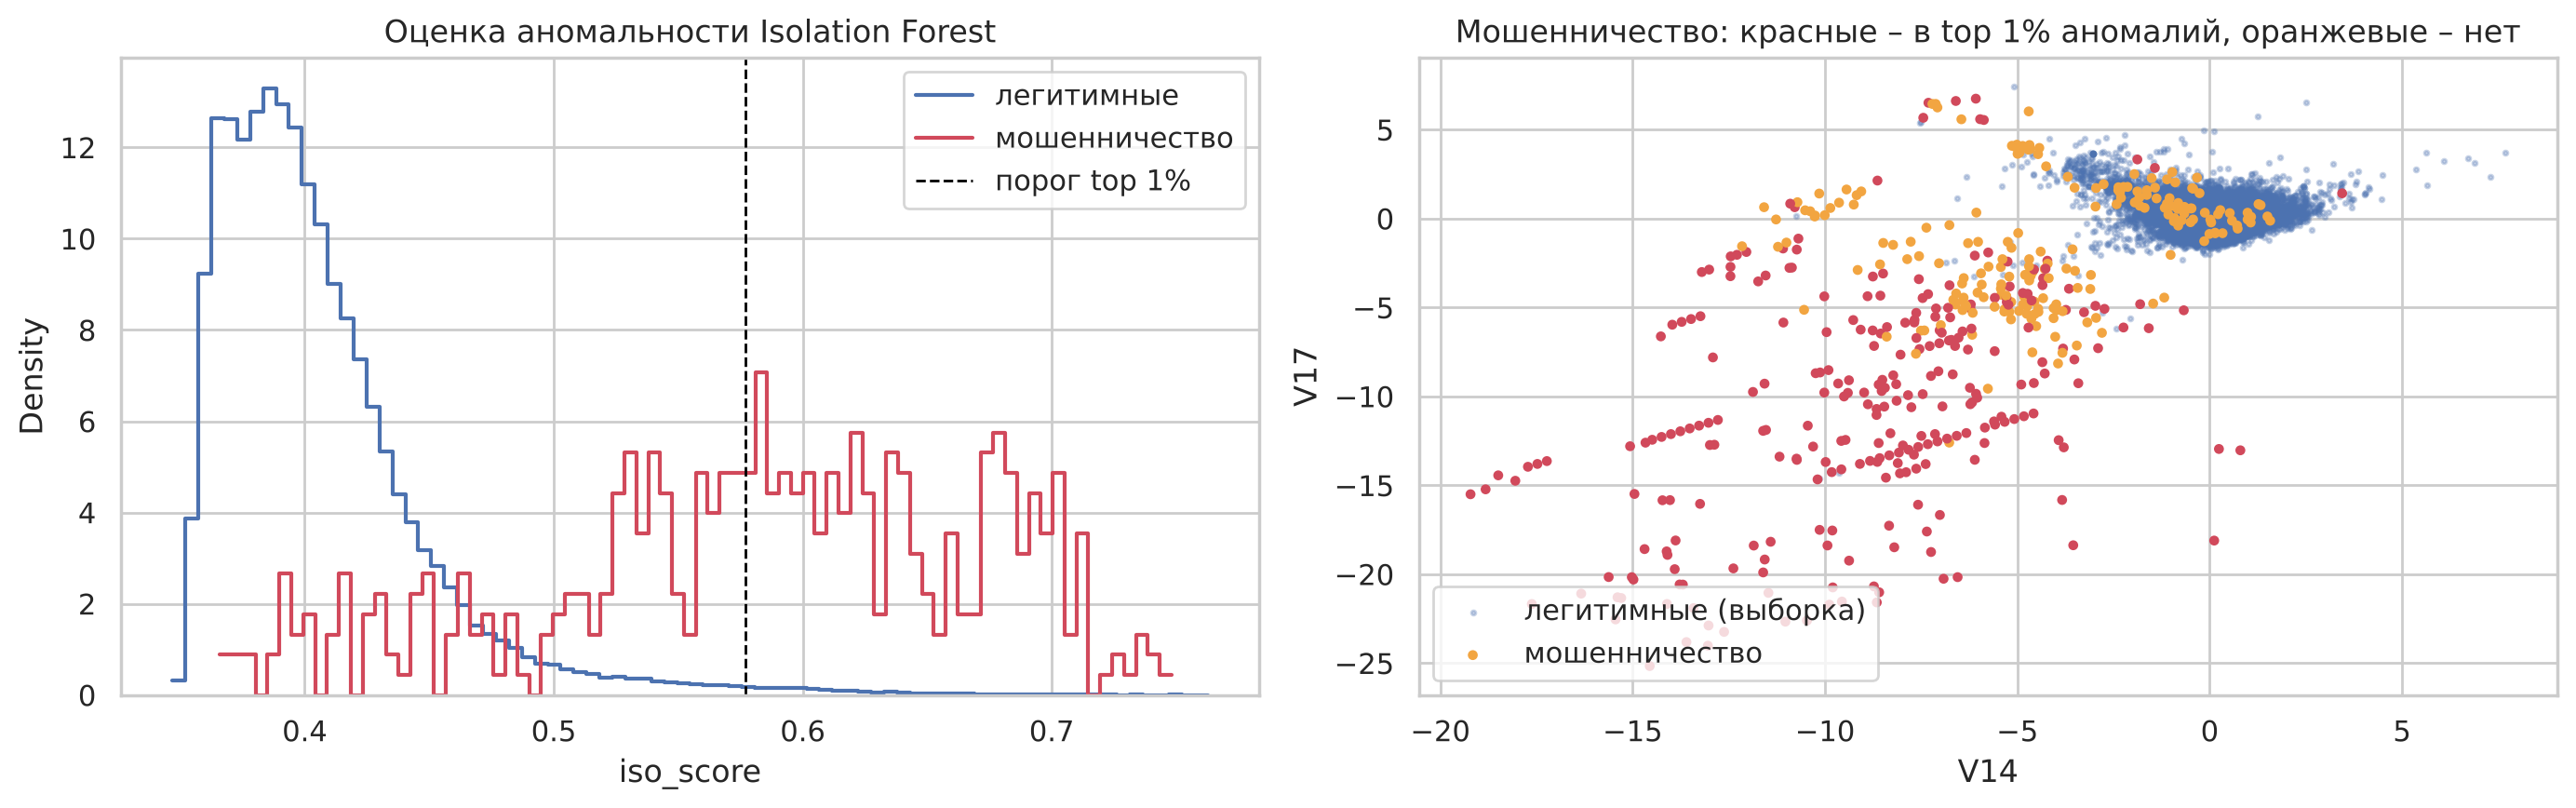

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for cls in [0, 1]:
    sns.histplot(df.loc[df['Class'] == cls, 'iso_score'], bins=80, stat='density', element='step', fill=False,
                 color=PAL[cls], ax=axes[0], label=['легитимные', 'мошенничество'][cls])
axes[0].axvline(thr, color='black', ls='--', lw=1, label='порог top 1%')
axes[0].legend()
axes[0].set_title('Оценка аномальности Isolation Forest')

bg = df[~pos].sample(20000, random_state=RS)
axes[1].scatter(bg['V14'], bg['V17'], s=3, alpha=0.3, color=PAL[0], label='легитимные (выборка)')
fr = df[pos]
axes[1].scatter(fr['V14'], fr['V17'], s=8, c=np.where(fr['iso_top1'], PAL[1], '#F2A541'),
                label='мошенничество')
axes[1].set_xlabel('V14')
axes[1].set_ylabel('V17')
axes[1].set_title('Мошенничество: красные – в top 1% аномалий, оранжевые – нет')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

Здесь видно три типа объектов:

1. Мошенничество, которое является глобальной аномалией. Это около 57% мошеннических операций, они попадают в top 1% по аномальности без всяких меток. У них экстремальные значения сразу в нескольких компонентах, такие операции находят и методы без учителя.
2. Мошенничество, похожее на норму. Остальные мошеннические операции лежат внутри облака нормальных (оранжевые точки около центра). Без меток их не найти, тут обучение с учителем должно дать основной выигрыш.
3. Нормальные операции, которые выглядят как аномалии. Почти весь top 1% (2570 из 2838) это честные операции, просто редкие. Из-за них у методов без учителя будет много ложных срабатываний и низкий precision.

PR-AUC у Isolation Forest получилась около 0.14. Это почти в 100 раз лучше случайной (0.0017), но от модели с учителем мы ждем заметно больше. Сравнивать будем на одном и том же разбиении.

## 11. Временная структура и потенциальные утечки

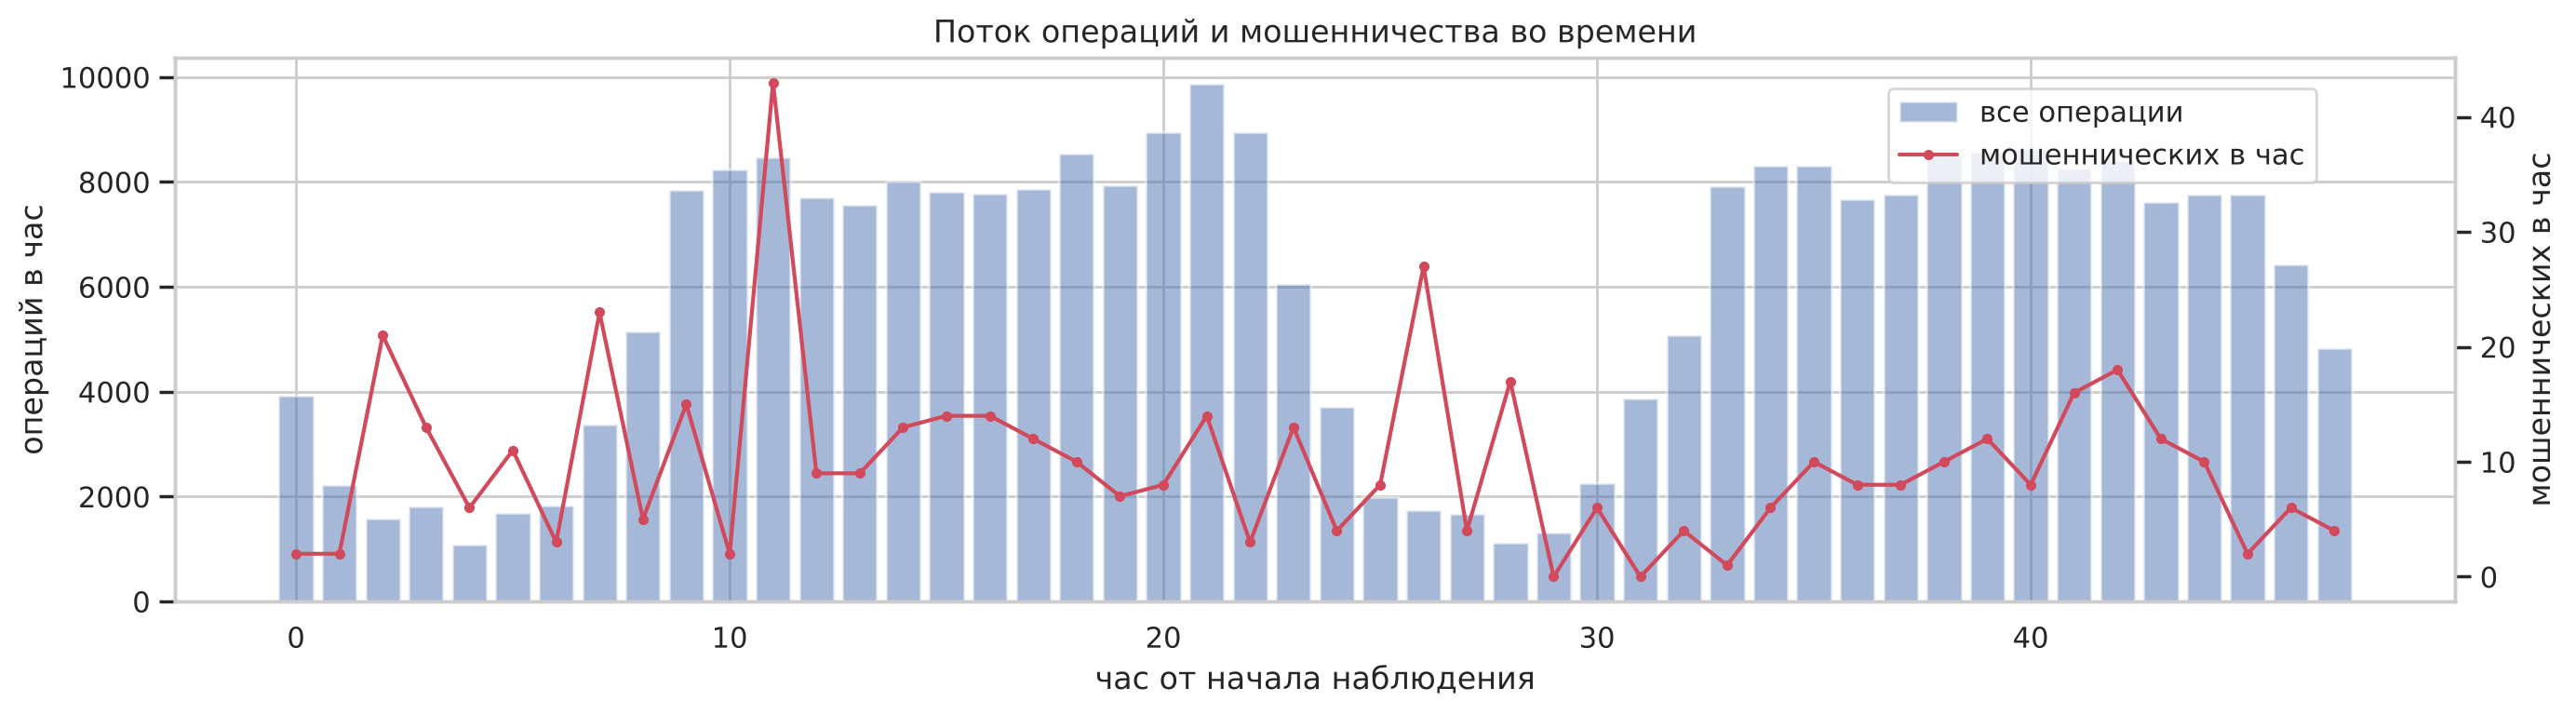

Доля мошенничества по суткам: {0.0: 0.00189, 1.0: 0.00144}


In [32]:
df['hour_abs'] = (df['Time'] // 3600).astype(int)
ts = df.groupby('hour_abs')['Class'].agg(['size', 'sum', 'mean'])
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.bar(ts.index, ts['size'], color=PAL[0], alpha=0.5, label='все операции')
ax1.set_ylabel('операций в час')
ax2 = ax1.twinx()
ax2.plot(ts.index, ts['sum'], color=PAL[1], marker='o', ms=3, label='мошеннических в час')
ax2.set_ylabel('мошеннических в час')
ax2.grid(False)
ax1.set_xlabel('час от начала наблюдения')
ax1.set_title('Поток операций и мошенничества во времени')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.show()
print('Доля мошенничества по суткам:', df.groupby(df['Time'] // 86400)['Class'].mean().round(5).to_dict())

Мошенничество идет неравномерно: бывают часы со всплесками до 20–40 операций, хотя обычно их единицы, похоже на серии атак. Доля мошенничества в первые и вторые сутки тоже разная (0.19% и 0.14%), то есть даже за два дня распределение таргета немного сдвигается.

Где может быть утечка и что с этим делаем:
- Дубликаты: одна копия в train, другая в test. Уже удалили до разбиения.
- PCA авторы обучали на всем датасете, то есть компоненты "видели" и тестовые данные. Исправить это нельзя, просто учитываем, что оценки на этом датасете немного оптимистичные.
- Абсолютное `Time`: модель может запомнить конкретные часы атак. Используем только `hour`.
- SMOTE или undersampling до разбиения: синтетические точки, построенные по тестовым объектам, попадут в train. Ресемплинг делаем только внутри train фолда, через `imblearn.Pipeline`.
- Скейлер и порог, подобранные на всех данных. Скейлер обучаем на train, порог подбираем на validation, тест трогаем один раз в конце.
- Нет id карты, поэтому нельзя разбить по группам, и операции одной карты могут оказаться и в train, и в test. Это ограничение датасета, временное разбиение немного помогает.

## 12. Схема разбиения данных

В реальности модель всегда применяется к будущим операциям, поэтому основное разбиение делаем по времени: сортируем по `Time`, первые 60% в train, следующие 20% в validation (для подбора гиперпараметров и порога), последние 20% в test.

In [33]:
d = df.sort_values('Time').reset_index(drop=True)
n = len(d)
d['split'] = np.select([d.index < 0.6 * n, d.index < 0.8 * n], ['train', 'valid'], 'test')
split_tab = d.groupby('split', sort=False).agg(n=('Class', 'size'), n_fraud=('Class', 'sum'), fraud_rate=('Class', 'mean'),
                                               t_from_h=('Time', lambda s: s.min() / 3600), t_to_h=('Time', lambda s: s.max() / 3600))
split_tab.round(4)

,n,n_fraud,fraud_rate,t_from_h,t_to_h
split,,,,,
train,170236,342,0.0020,0.0000,33.4425
valid,56745,57,0.0010,33.4428,40.3428
test,56745,74,0.0013,40.3428,47.9978


In [34]:
test = d[d['split'] == 'test']
rng = np.random.default_rng(RS)
idx = np.arange(len(test))
y, s = test['Class'].to_numpy(), -test['V14'].to_numpy()
boot = []
for _ in range(500):
    b = rng.choice(idx, len(idx), replace=True)
    boot.append(average_precision_score(y[b], s[b]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print('PR-AUC простого правила -V14 на тесте:', round(average_precision_score(y, s), 3))
print('95% бутстреп-интервал:', round(lo, 3), '-', round(hi, 3))

PR-AUC простого правила -V14 на тесте: 0.639
95% бутстреп-интервал: 0.524 - 0.741


По таблице видно, что доля класса в частях разная: в train 0.20%, в validation и test 0.10–0.13%. Если подобрать порог при одной доле мошенничества, при другой будет другой precision, поэтому устойчивость к доле класса надо проверять отдельно.

Даже у простого правила по одной `V14` 95% интервал PR-AUC на тесте получился широким, примерно 0.52–0.74. В тесте всего 74 мошеннические операции, поэтому разница между моделями в несколько сотых вполне может быть шумом. Итого:
- основное разбиение по времени 60 / 20 / 20, тест используем один раз в конце
- для подбора гиперпараметров на train+valid можно брать `TimeSeriesSplit`
- метрики считаем вместе с бутстреп-интервалами, а модели сравниваем на одних и тех же бутстреп-выборках
- устойчивость к доле мошенничества проверим, прореживая класс 1 в тесте (например, до 0.1% и 0.05%) и смотря, как падают PR-AUC и precision при выбранном пороге

## 13. Выводы

1. В датасете 284 807 операций за двое суток, 31 числовой признак. Явных пропусков и логических ошибок нет. Нашли и удалили 1081 полный дубликат, иначе они давали бы утечку между train и test. После этого осталось 473 мошеннические операции.
2. Мошенничества около 0.17%, то есть 1 к 578. Accuracy не подходит, ROC-AUC слишком оптимистична, поэтому основная метрика PR-AUC (для случайной модели 0.0017), а еще recall при фиксированном precision и матрица ошибок при выбранном пороге.
3. Нулевые суммы (около 0.6% операций), скорее всего, отдельный тип операции, вероятно, проверка карты. Мошенничества среди них примерно в 9 раз больше, поэтому делаем из этого отдельный признак.
4. У компонент очень тяжелые хвосты, и выбросы в основном и есть мошенничество, так что их не удаляем. Для методов, чувствительных к масштабу, используем робастное масштабирование, для `Amount` берем `log1p`.
5. Самые полезные компоненты `V14`, `V12`, `V10`, `V17`, `V4`, `V11`, `V3`, `V16`, а `V13`, `V15`, `V22`–`V26` почти ничего не дают. Зависимость от суммы U-образная, ночью мошенничества в разы больше, поэтому нужны нелинейные модели и признак часа.
6. Внутри класса 1 компоненты сильно коррелируют, мошенничество вытянуто "хвостами" от облака нормальных операций. Примерно 57% мошенничества Isolation Forest без меток ставит в top 1% аномалий, остальное от нормы не отличить, а большинство "аномалий" это честные операции. Поэтому мы ожидаем, что методы без учителя будут хуже XGBoost, и это надо будет показать в экспериментах.
7. Разбиваем по времени 60 / 20 / 20 после удаления дубликатов, ресемплинг и масштабирование только внутри train, порог выбираем на validation. Положительных объектов мало, поэтому к метрикам добавляем бутстреп-интервалы.

Что дальше: на этом датасете будем сравнивать Isolation Forest, One-Class SVM и LOF с XGBoost и логистической регрессией, пробовать `scale_pos_weight`, undersampling и SMOTE и подбирать порог под ограничение на precision. Минус датасета в том, что признаки обезличены, и SHAP можно будет интерпретировать только на уровне компонент. Содержательную интерпретацию будем делать на PaySim и Sparkov.